# Детекция объектов и Семантическая Сегментация

> В этом уроке мы научимся решать две важные задачи компьютерного зрения: семантическую сегментацию и детекцию объектов на изображении. Мы углубимся в принципы работы нейронных сетей для этих задач, разберем ключевые архитектуры и их эволюцию, а также подробно рассмотрим практическую реализацию на PyTorch.


## План ноутбука

1.  **Семантическая Сегментация:**
    *   Постановка задачи и мотивация
    *   Данные и метрики качества
    *   Функция потерь
    *   Архитектуры (FCN, U-Net)
    *   Практическая реализация и обучение UNet
2.  **Детекция Объектов:**
    *   Постановка задачи и мотивация
    *   Non-Maximum Suppression (NMS)
    *   Метрики качества (Precision, Recall, mAP)
    *   Архитектуры (R-CNN, Fast R-CNN, Faster R-CNN, YOLO)
    *   Практическая реализация и обучение Faster R-CNN

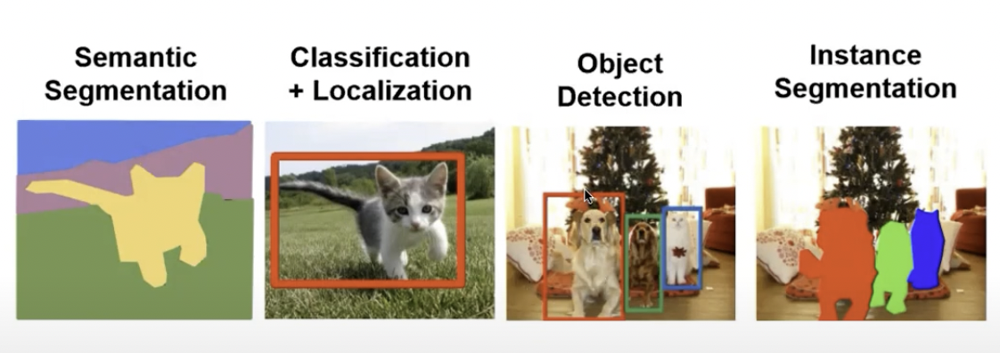

## 1. Семантическая Сегментация

Задача семантической сегментации заключается в том, чтобы **классифицировать каждый пиксель изображения** по принадлежности к определенному классу. Это отличается от обычной классификации изображений, где мы присваиваем один класс всему изображению.

**Мотивация:**

Представьте, что вы хирург и смотрите на рентгеновский снимок ноги пациента. Задача "есть перелом или нет?" - это классификация. Но гораздо важнее знать *точное местоположение* перелома. Семантическая сегментация позволяет выделить область перелома пиксель за пикселем, что дает врачу значительно больше информации.

Другие примеры:
*   **Автономное вождение:** Выделение дорог, пешеходов, других машин, знаков на пиксельном уровне для понимания окружающей среды.
*   **Медицина:** Точное выделение опухолей, органов на МРТ/КТ снимках.
*   **Геоинформационные системы:** Анализ спутниковых снимков (выделение лесов, водоемов, городской застройки).

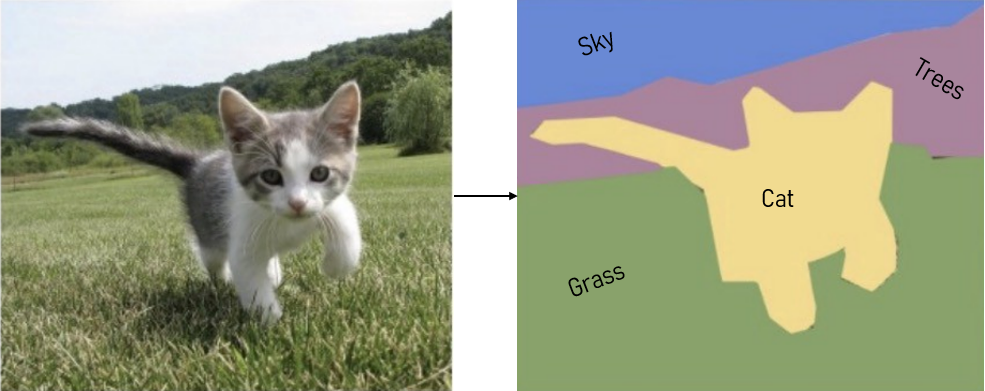

### Постановка задачи

*   **Входные данные:** Изображение (например, RGB).
*   **Выходные данные:** Карта сегментации (или "маска") того же размера, что и входное изображение, где каждый пиксель содержит метку класса.
*   **Золотой стандарт сегментации:** Для обучения у нас есть исходное изображение и соответствующая ему "маска правды" (`ground truth mask`), где каждый пиксель уже размечен вручную.

**Примеры данных:**
*   **PASCAL VOC (2007-2012):** Один из старейших и наиболее популярных датасетов для сегментации и детекции, содержащий 20 категорий объектов + фон.
*   **CITYSCAPES:** Датасет для автономного вождения, содержащий изображения городских сцен с очень подробной пиксельной разметкой (5000 обучающих изображений, 19 классов).
*   **OXFORD-IIIT PETS:** Датасет с изображениями домашних животных (кошек и собак) различных пород, для которых есть как классификация, так и сегментационные маски.

Пример сегментации из датасета Oxford Pets. Здесь маска содержит три класса: само животное (желтый), его границы (красный) и фон (синий).

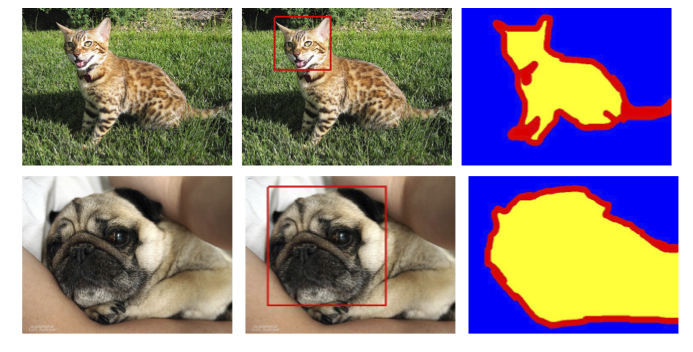

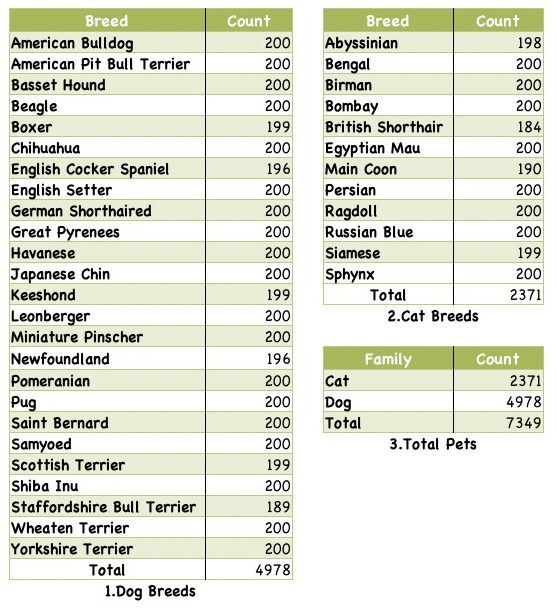

**Почему датасеты для сегментации кажутся маленькими?**

На первый взгляд, датасеты для сегментации (например, Oxford Pets с ~7500 изображениями) могут показаться небольшими по сравнению с миллионами изображений в ImageNet. Однако важно помнить:
*   В задаче классификации мы обучаем модель предсказывать *один* класс на *одно* изображение.
*   В задаче семантической сегментации мы классифицируем *каждый пиксель* изображения.
*   Даже если изображение имеет размер 100x100 пикселей, это означает 10 000 отдельных классификаций на одном изображении. Таким образом, эффективное количество "точек данных" для классификации значительно возрастает (в 10 000 раз для 100x100 изображений). Это помогает модели обучаться даже на относительно небольшом количестве изображений.

### Метрики качества

Для оценки качества семантической сегментации используются следующие метрики:

1.  **Попиксельная доля верных ответов (Pixel Accuracy):**
    Это самая простая метрика, которая показывает, какая доля пикселей была классифицирована правильно.
    $$\text{Accuracy}(y, a) = \dfrac{1}{n}\sum\limits_{i=1}^{n}[y_i = a_i]$$
    Где:
    *   $y_i$ — истинный класс $i$-го пикселя.
    *   $a_i$ — предсказанный класс $i$-го пикселя.
    *   $n$ — общее количество пикселей на изображении.
    *   $[y_i = a_i]$ — индикаторная функция, которая равна 1, если предсказанный класс совпадает с истинным, и 0 в противном случае.

    **Проблема Pixel Accuracy:** Эта метрика может быть обманчивой, если классы сильно несбалансированы. Например, если 95% изображения занимает фон, а объект — только 5%, модель, которая всегда предсказывает "фон", достигнет 95% точности, но будет совершенно бесполезной.

2.  **Мера Жаккара (Jaccard Index) / Intersection Over Union (IoU):**
    Эта метрика гораздо более предпочтительна для задач сегментации, так как она учитывает пересечение предсказанной области с истинной. IoU рассчитывается для *каждого класса* по отдельности, а затем может быть усреднено по всем классам.
    $$J_k(y, a) = \dfrac{\text{Площадь пересечения}(y_k, a_k)}{\text{Площадь объединения}(y_k, a_k)} = \dfrac{\sum\limits_{i=1}^{n}[y_i = k][a_i = k]}{\sum\limits_{i=1}^{n}\max([y_i = k], [a_i = k])}$$
    Где:
    *   $y_k$ — пиксели, которые *на самом деле* принадлежат классу $k$.
    *   $a_k$ — пиксели, которые *модель предсказала* как принадлежащие классу $k$.
    *   $[y_i = k]$ — индикаторная функция, равна 1, если $i$-й пиксель принадлежит классу $k$ в истинной маске.
    *   $[a_i = k]$ — индикаторная функция, равна 1, если $i$-й пиксель принадлежит классу $k$ в предсказанной маске.
    *   $\sum\limits_{i=1}^{n}[y_i = k][a_i = k]$: Это количество пикселей, которые *одновременно* являются классом $k$ в истинной маске И предсказаны как класс $k$ моделью (т.е., **пересечение**).
    *   $\sum\limits_{i=1}^{n}\max([y_i = k], [a_i = k])$: Это количество пикселей, которые являются классом $k$ *либо* в истинной маске, *либо* в предсказанной маске, *либо* и там, и там (т.е., **объединение**).

    Интуитивно, IoU показывает, насколько хорошо предсказанная маска (оранжевая) перекрывает истинную маску (синюю). Значение 1 означает идеальное совпадение, 0 — отсутствие совпадений.

    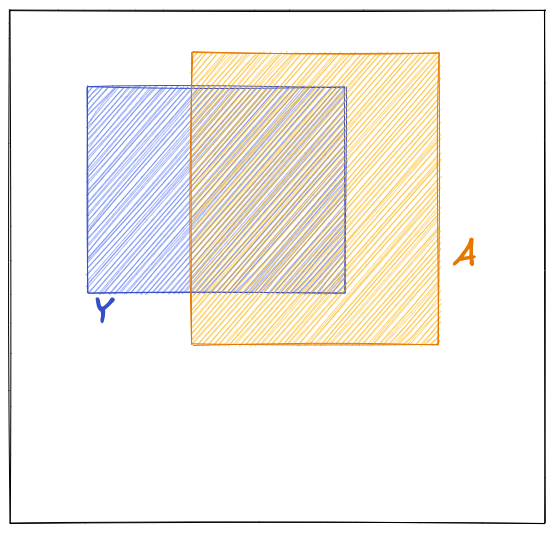

    **Пример:**
    *   Если предсказано 10 пикселей как класс "кошка" и 8 из них действительно были "кошкой" (TP=8), а 2 были фоном (FP=2).
    *   Истинная маска имела 10 пикселей "кошка", но модель нашла только 8 (TP=8), а 2 пропустила (FN=2).
    *   Площадь пересечения = TP = 8.
    *   Площадь объединения = TP + FP + FN = 8 + 2 + 2 = 12.
    *   IoU = 8 / 12 = 0.67.

### Функция потерь

Поскольку семантическая сегментация — это задача попиксельной классификации, мы можем использовать ту же функцию потерь, что и для многоклассовой классификации, но применяя ее к каждому пикселю. Наиболее часто используется **Cross-Entropy Loss (кросс-энтропийная потеря)**.

Вместо того чтобы классифицировать одно изображение в целом, мы классифицируем каждый пиксель независимо. Модель выдает вероятности принадлежности каждого пикселя к каждому классу. Затем эти вероятности сравниваются с истинной меткой класса для каждого пикселя, и потери суммируются по всем пикселям изображения.

$$L = -\sum_{i=1}^{N_{pixels}} \sum_{c=1}^{C} y_{i,c} \log(p_{i,c})$$
Где:
*   $N_{pixels}$ — общее количество пикселей.
*   $C$ — количество классов.
*   $y_{i,c}$ — индикаторная функция (1, если $i$-й пиксель относится к классу $c$ в истинной маске, иначе 0).
*   $p_{i,c}$ — предсказанная моделью вероятность того, что $i$-й пиксель относится к классу $c$.

По сути, это то же, что и обычная Cross-Entropy, но применяемая к "вытянутым" в один вектор предсказаниям и истинным меткам для всех пикселей.

## 2. Архитектуры нейронных сетей для семантической сегментации

### Fully Convolutional Network (FCN)

[Оригинальная статья: Fully Convolutional Networks for Semantic Segmentation (2014)](https://arxiv.org/abs/1411.4038)

FCN была одной из первых успешных архитектур для семантической сегментации, которая показала, как можно адаптировать уже существующие сверточные сети для этой задачи.

**Основная идея:**
Заменить все полносвязные (fully connected) слои классической сверточной нейронной сети (например, AlexNet, VGG) на сверточные слои. Это позволяет сети принимать на вход изображения произвольного размера и выдавать карту активаций (feature map) также произвольного размера, которую затем можно увеличить до размера исходного изображения.

**Принцип работы:**

1.  **Использование предобученного классификатора:** Берем архитектуру вроде AlexNet или VGG, которая уже хорошо умеет извлекать признаки из изображений для задачи классификации.
2.  **Удаление полносвязных слоев:** Все полносвязные слои заменяются на сверточные слои. Свертка 1x1 с количеством выходных каналов, равным числу классов, эффективно действует как классификатор для каждого пространственного положения.
3.  **Потеря пространственной информации:** Проблема в том, что в классических сетях (как AlexNet) часто используются `MaxPooling` слои, которые уменьшают пространственное разрешение карты признаков. Это отлично для классификации (нам не важно *где* объект, важно *что* он есть), но очень плохо для сегментации (нам нужно точное *где*).
    *   Представьте, что у вас есть изображение котенка. MaxPooling несколько раз уменьшает его размер, сохраняя информацию о *наличии* котенка, но теряя детали о его *конкретном контуре и положении*.
4.  **Повышение разрешения (Upsampling):** Чтобы получить маску сегментации исходного размера, необходимо "развернуть" маленькую карту активаций обратно. В ранних FCN для этого использовались простые методы, такие как **интерполяция ближайшего соседа (nearest neighbor interpolation)** или **двулинейная интерполяция (bilinear interpolation)**.
    *   **Интерполяция ближайшего соседа:** Просто копирует значения пикселей, чтобы заполнить новую, увеличенную сетку. Например, пиксель 2x2 (1,2,3,4) становится 4x4, где каждая "четверть" заполнена одним из исходных пикселей. Это дает очень блочные, нечеткие края.

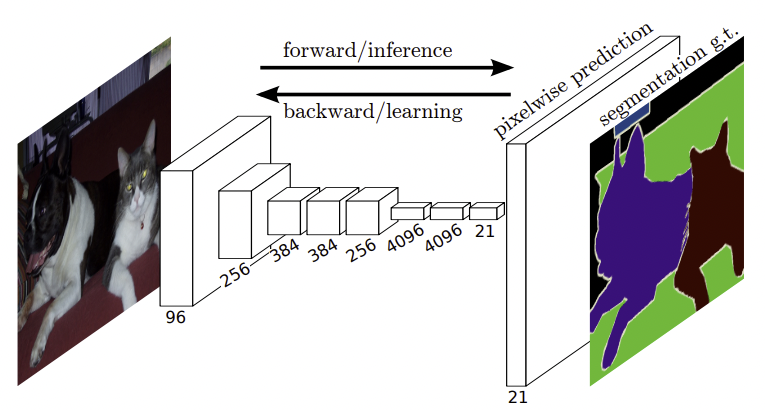

_Схема Fully Convolutional Network. Сверху: классическая VGG. Снизу: FCN, где последние полносвязные слои заменены на сверточные, а затем выход увеличен._

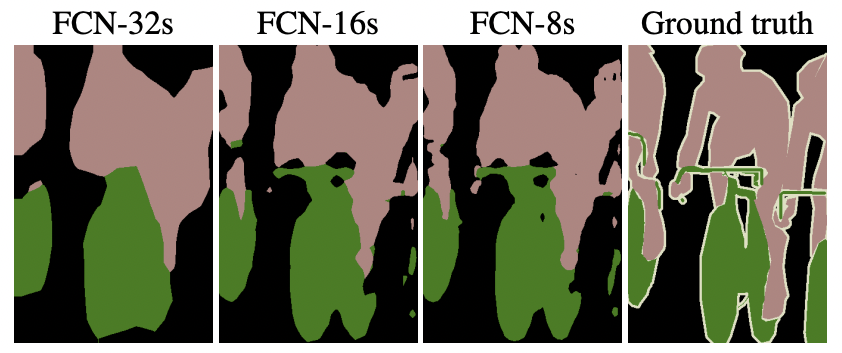

_Пример результатов FCN. Видно, что края объектов очень нечеткие и напоминают "пятна"._

**Минусы FCN:**
*   **Низкая точность локализации:** Из-за многократного `MaxPooling` в сверточной части теряется детальная пространственная информация о границах объектов. Простые методы апсемплинга не могут восстановить эту информацию.
*   **"Пятнистость" сегментации:** Результаты часто выглядят размытыми и неточными по краям объектов.
*   **Игнорирование низкоуровневых признаков:** Модель полагается в основном на высокоуровневые, семантические признаки, извлеченные из глубоких слоев, но теряет полезные детали из ранних слоев, которые содержат информацию о четких границах и текстурах.

### U-Net

[Оригинальная статья: U-Net: Convolutional Networks for Biomedical Image Segmentation (2015)](https://arxiv.org/abs/1505.04597)

U-Net была разработана для сегментации медицинских изображений, где требуется очень высокая точность границ, но быстро нашла применение и в других областях. Она значительно улучшила проблему потери пространственной информации FCN.

**Основная идея:**
Сочетание "сжимающего" пути (кодировщик, encoder) и "расширяющего" пути (декодировщик, decoder) с **skip connections (связями пропуска)**, которые передают детальную, низкоуровневую пространственную информацию из кодировщика в декодировщик. Архитектура названа "U-Net" из-за своей характерной U-образной формы.

**Принцип работы (структура "Encoder-Decoder" с Skip Connections):**

1.  **Путь кодировщика (Contracting Path / Encoder):**
    *   Это обычная сверточная сеть, которая последовательно применяет сверточные слои и `MaxPooling` (или свертки с большим шагом `stride`).
    *   Каждый шаг уменьшает пространственное разрешение изображения, но увеличивает количество каналов (глубину).
    *   Задача кодировщика: извлекать **высокоуровневые, контекстуальные признаки** (что за объект?) и сжимать пространственные размеры. На дне этой U-образной структуры находится "бутылочное горлышко" (bottleneck), где изображение имеет наименьшее пространственное разрешение, но наибольшую глубину каналов.
    *   **Skip Connections:** На каждом этапе сжатия, выход сверточного блока *сохраняется* для последующей передачи в соответствующий этап декодировщика.

2.  **Путь декодировщика (Expansive Path / Decoder):**
    *   Начинается с самой нижней, наиболее сжатой карты признаков.
    *   Последовательно **повышает пространственное разрешение** с помощью слоев апсемплинга (UpSampling).
    *   На каждом шаге апсемплинга происходит **конкатенация (объединение по каналам)** карты признаков из текущего этапа декодировщика с соответствующей картой признаков, сохраненной из кодировщика (через skip connection).
    *   Задача декодировщика: восстановить **детальную пространственную информацию** (где именно находится объект?) и уменьшить количество каналов до числа классов.

**Роль Skip Connections:**
*   **Передача низкоуровневых признаков:** Ранние слои кодировщика содержат очень точную информацию о границах, текстурах и мелких деталях. `MaxPooling` в кодировщике эту информацию теряет.
*   **Комбинация контекста и локализации:** Skip connections позволяют декодировщику использовать как высокоуровневую контекстуальную информацию (из глубоких слоев кодировщика и текущего этапа декодировщика), так и точную пространственную информацию (из ранних слоев кодировщика). Это критически важно для получения точных границ сегментации.

**Upsampling в UNet (Транспонированные свертки vs. Интерполяция):**
*   **Транспонированная свертка (Transposed Convolution / Deconvolution):** В оригинальной UNet и многих других архитектурах используется транспонированная свертка. Это *обучаемый* способ увеличения пространственного разрешения. Она "разворачивает" сверточную операцию, распределяя значения входного пикселя на несколько выходных. Это более сложно, но позволяет модели *учиться* оптимальному способу апсемплинга.
*   **Интерполяция (например, `nn.functional.interpolate`):** В некоторых реализациях, включая нашу в этом ноутбуке, для простоты используется обычная интерполяция (например, билинейная). Это *необучаемый* способ апсемплинга, который просто увеличивает изображение, основываясь на математических правилах, без использования весов сети. Это проще реализовать и может дать достаточно хорошие результаты для вводных задач, но менее гибко, чем транспонированная свертка.

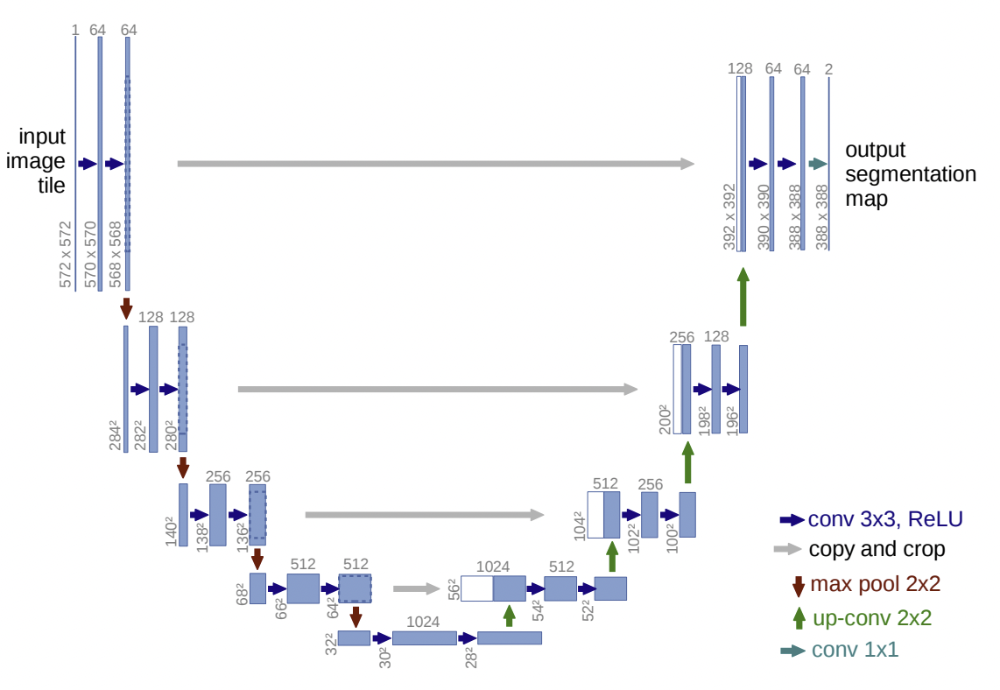

_Схема U-Net. Серые стрелочки обозначают Skip Connections._


## 3. Практическая реализация для семантической сегментации

В этой части мы реализуем и обучим упрощенную версию U-Net для задачи семантической сегментации на датасете Oxford Pets.

In [1]:
#!g1.1
import torch
import matplotlib.pyplot as plt
import torchvision.transforms as T
from torchvision.datasets import OxfordIIITPet
from torch.utils.data import DataLoader
from tqdm import tqdm
import torch.nn as nn
import numpy as np
from PIL import Image
from IPython.display import clear_output

In [2]:
# Проверяем наличие GPU и устанавливаем устройство
device = torch.device('cuda:0' if torch.cuda.is_available() else 'cpu')
print(f"Используемое устройство: {device}")
if torch.cuda.is_available():
    print(f"Имя GPU: {torch.cuda.get_device_name()}")

Используемое устройство: cuda:0
Имя GPU: NVIDIA GeForce RTX 4060 Ti


In [3]:
# 1. Загрузка и подготовка данных для семантической сегментации

# Инициализируем датасет OxfordIIITPet.
# target_types='segmentation' указывает, что нам нужны сегментационные маски.
# dataset = OxfordIIITPet('/home/jupyter/mnt/datasets/pets', target_types='segmentation')
# Если вы работаете не в Яндекс.Датасфере или хотите загрузить датасет локально:
# dataset = OxfordIIITPet('./data', download=True, target_types='segmentation')
# В Jupyter DataSphere датасет уже доступен по пути '/home/jupyter/mnt/datasets/pets'
dataset = OxfordIIITPet('/home/jupyter/mnt/datasets/pets', target_types='segmentation')

In [4]:
# Посмотрим на первый элемент датасета.
# Он возвращает кортеж из двух PIL-изображений: исходного изображения и его маски.
print(f"Пример первого элемента датасета: {dataset[0]}")
print(f"Тип исходного изображения: {type(dataset[0][0])}")
print(f"Тип маски сегментации: {type(dataset[0][1])}")

Пример первого элемента датасета: (<PIL.Image.Image image mode=RGB size=394x500 at 0x2160B1CAE40>, <PIL.PngImagePlugin.PngImageFile image mode=L size=394x500 at 0x2160B2CB3E0>)
Тип исходного изображения: <class 'PIL.Image.Image'>
Тип маски сегментации: <class 'PIL.PngImagePlugin.PngImageFile'>



Исходное изображение:


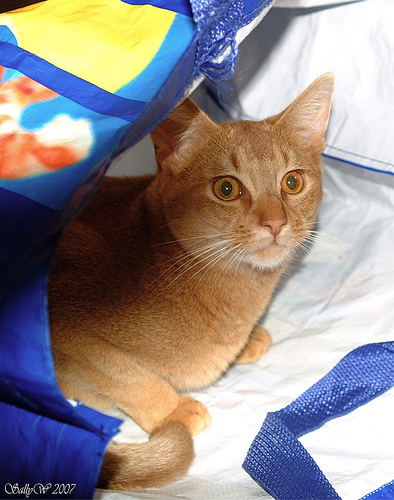

In [5]:
# Визуализируем исходное изображение
print("\nИсходное изображение:")
display(dataset[0][0])

Маска сегментации (значения пикселей 1, 2, 3 для классов):


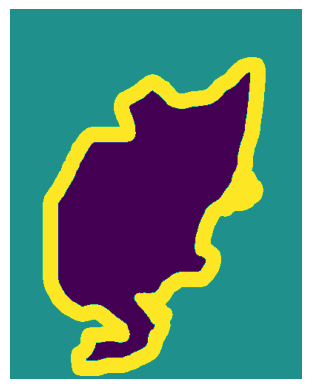

In [6]:
# Визуализируем маску сегментации
print("Маска сегментации (значения пикселей 1, 2, 3 для классов):")
plt.imshow(dataset[0][1])
plt.axis('off') # Убираем оси для лучшей визуализации
plt.show()


Другое изображение из датасета и его маска:


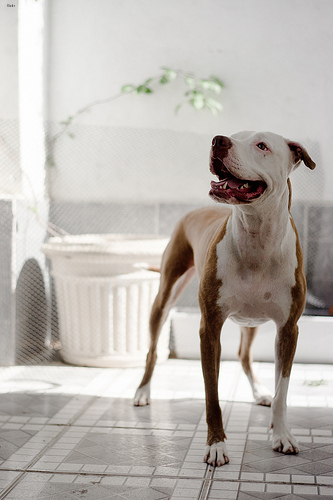

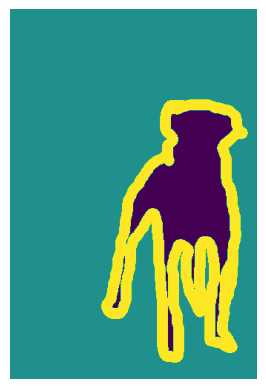

In [7]:
# Посмотрим на другое изображение и его маску
print("\nДругое изображение из датасета и его маска:")
display(dataset[100][0])
plt.imshow(dataset[100][1])
plt.axis('off')
plt.show()

In [8]:
# 2. Определение трансформаций для изображений и масок

# Трансформации для входного изображения (RGB)
transform = T.Compose(
    [
        # Изменяем размер изображения до 128x128 пикселей.
        # Это уменьшает вычислительную нагрузку, но может привести к потере мелких деталей.
        T.Resize((128, 128)),
        # Преобразуем изображение из PIL Image в PyTorch Tensor.
        # Это также нормализует значения пикселей в диапазон [0, 1].
        T.ToTensor(),
    ]
)

# Трансформации для маски сегментации (одноканальное изображение)
target_transform = T.Compose(
    [
        # Изменяем размер маски до того же размера, что и изображение.
        # Важно использовать тот же размер, чтобы маска соответствовала изображению.
        T.Resize((128, 128)),
        # Преобразуем маску из PIL Image в PyTorch Tensor.
        # Для масок это обычно означает тензор с типом uint8.
        T.PILToTensor(),
        # Лямбда-функция для преобразования значений пикселей в маске.
        # Датасет OxfordIIITPet использует метки 1, 2, 3 для классов (животное, граница, фон).
        # Однако PyTorch's CrossEntropyLoss ожидает, что метки классов будут начинаться с 0.
        # Поэтому мы вычитаем 1 из каждого пикселя, чтобы получить метки 0, 1, 2.
        # .long() преобразует тензор в тип Long, который необходим для CrossEntropyLoss.
        T.Lambda(lambda x: (x - 1).long())
    ]
)

In [9]:
# Создаем обучающий и валидационный датасеты с примененными трансформациями
# split='train' для обучающей выборки, split='test' для валидационной.
train_dataset = OxfordIIITPet(
    '/home/jupyter/mnt/datasets/pets',
    transform=transform,
    target_transform=target_transform,
    target_types='segmentation'
)
valid_dataset = OxfordIIITPet(
    '/home/jupyter/mnt/datasets/pets',
    transform=transform,
    split='test',
    target_transform=target_transform,
    target_types='segmentation'
)

In [10]:
# 3. Создание DataLoader'ов

# DataLoader помогает эффективно загружать данные батчами, перемешивать их и
# выполнять параллельную загрузку (num_workers).
train_loader = DataLoader(train_dataset, batch_size=64, shuffle=True, num_workers=0, pin_memory=True)
valid_loader = DataLoader(valid_dataset, batch_size=64, shuffle=True, num_workers=0, pin_memory=True)

In [11]:
# 4. Определение функций обучения и оценки

def train(model) -> float:
    """
    Выполняет один цикл обучения модели на обучающем датасете.
    Возвращает среднюю потерю и среднюю попиксельную точность на обучающей выборке.
    """
    model.train() # Переключаем модель в режим обучения (включает Dropout, BatchNorm и т.д.)

    train_loss = 0
    total_pixels = 0
    correct_pixels = 0

    # Итерируемся по батчам в DataLoader'е
    for x, y in tqdm(train_loader, desc='Train'):
        bs = y.size(0) # Размер текущего батча

        # Перемещаем входные изображения и маски на GPU
        # y.squeeze(1) удаляет лишнюю размерность, если маска была (batch_size, 1, H, W)
        # CrossEntropyLoss ожидает входной тензор shape (N, C, H, W) и целевой тензор (N, H, W)
        x, y = x.to(device), y.squeeze(1).to(device)

        optimizer.zero_grad() # Обнуляем градиенты перед каждым шагом оптимизации

        output = model(x) # Выполняем прямой проход (forward pass)

        # Выход модели (output) имеет размерность (batch_size, num_classes, H, W).
        # Целевая маска (y) имеет размерность (batch_size, H, W).
        # CrossEntropyLoss ожидает, что входной тензор будет (N, C, D1, D2, ...)
        # и целевой тензор будет (N, D1, D2, ...).
        # Мы преобразуем их так, чтобы они соответствовали формату:
        # output.reshape(bs, 3, -1) превращает (bs, 3, H, W) в (bs, 3, H*W)
        # y.reshape(bs, -1) превращает (bs, H, W) в (bs, H*W)
        # Это позволяет CrossEntropyLoss работать с каждым пикселем как с отдельной точкой данных
        # для классификации, но сохраняя батчевую структуру.
        loss = loss_fn(output.reshape(bs, 3, -1), y.reshape(bs, -1))

        train_loss += loss.item() # Добавляем значение потерь к общей сумме

        loss.backward() # Выполняем обратный проход (backward pass) для вычисления градиентов

        optimizer.step() # Делаем шаг оптимизации, обновляя веса модели

        # Рассчитываем попиксельную точность (accuracy)
        # output.max(dim=1) возвращает максимальное значение и его индекс по размерности классов (dim=1)
        _, y_pred = output.max(dim=1) # y_pred имеет предсказанный класс для каждого пикселя
        total_pixels += y.numel() # Общее количество пикселей в батче
        correct_pixels += (y == y_pred).sum().item() # Количество правильно предсказанных пикселей

    train_loss /= len(train_loader) # Средняя потеря за эпоху
    accuracy = correct_pixels / total_pixels # Общая попиксельная точность

    return train_loss, accuracy


@torch.inference_mode() # Отключает вычисление градиентов, ускоряет инференс и экономит память
def evaluate(model, loader) -> tuple[float, float]:
    """
    Оценивает модель на валидационном или тестовом датасете.
    Возвращает среднюю потерю и среднюю попиксельную точность.
    """
    model.eval() # Переключаем модель в режим оценки (отключает Dropout, BatchNorm и т.д.)

    total_loss = 0
    total_pixels = 0
    correct_pixels = 0

    for x, y in tqdm(loader, desc='Evaluation'):
        bs = y.size(0)

        x, y = x.to(device), y.squeeze(1).to(device)

        output = model(x)

        loss = loss_fn(output.reshape(bs, 3, -1), y.reshape(bs, -1))

        total_loss += loss.item()

        _, y_pred = output.max(dim=1)
        total_pixels += y.numel()
        correct_pixels += (y == y_pred).sum().item()

    total_loss /= len(loader)
    accuracy = correct_pixels / total_pixels

    return total_loss, accuracy


def plot_stats(
    train_loss: list[float],
    valid_loss: list[float],
    train_accuracy: list[float],
    valid_accuracy: list[float],
    title: str
):
    """
    Строит графики потерь и точности для обучения и валидации.
    """
    plt.figure(figsize=(16, 8))
    plt.title(title + ' loss')
    plt.plot(train_loss, label='Train loss')
    plt.plot(valid_loss, label='Valid loss')
    plt.legend()
    plt.grid()
    plt.show()

    plt.figure(figsize=(16, 8))
    plt.title(title + ' accuracy')
    plt.plot(train_accuracy, label='Train accuracy')
    plt.plot(valid_accuracy, label='Valid accuracy')
    plt.legend()
    plt.grid()
    plt.show()


@torch.inference_mode()
def visualize(model, batch):
    """
    Визуализирует предсказания модели для батча изображений.
    Показывает оригинальное изображение, истинную маску и предсказанную маску.
    """
    model.eval() # Модель в режиме оценки

    xs, ys = batch # Распаковываем батч на изображения и маски
    
    to_pil = T.ToPILImage() # Вспомогательная функция для преобразования тензора в PIL Image

    for i, (x, y) in enumerate(zip(xs, ys)):
        # x.unsqueeze(0) добавляет размерность батча (из (C, H, W) в (1, C, H, W))
        # .cuda() перемещает тензор на GPU для предсказания
        # .squeeze(0) удаляет размерность батча обратно после предсказания
        # .max(dim=0)[1] берет индекс максимального значения (класс) для каждого пикселя
        prediction = model(x.unsqueeze(0).to(device)).squeeze(0).max(dim=0)[1]

        fig, ax = plt.subplots(1, 3, figsize=(24, 8), facecolor='white')

        # Оригинальное изображение
        ax[0].imshow(to_pil(x.cpu())) # Переносим на CPU для визуализации
        ax[0].axis('off')
        ax[0].set_title('Original image')

        # Истинная маска сегментации
        # y.to(torch.uint8) преобразует метки классов в uint8 для корректной визуализации
        ax[1].imshow(to_pil(y.to(torch.uint8)))
        ax[1].axis('off')
        ax[1].set_title('Segmentation mask (Ground Truth)')

        # Предсказанная маска сегментации
        ax[2].imshow(to_pil(prediction.cpu().to(torch.uint8)))
        ax[2].axis('off')
        ax[2].set_title('Prediction')

        plt.subplots_adjust(wspace=0, hspace=0.1) # Убираем отступы между графиками
        plt.show()

        if i >= 4: # Визуализируем только первые 5 изображений из батча
            break


def whole_train_valid_cycle(model, num_epochs, title):
    """
    Запускает полный цикл обучения и валидации модели.
    """
    train_loss_history, valid_loss_history = [], []
    train_accuracy_history, valid_accuracy_history = [], []

    # Берем один батч из валидационного датасета для регулярной визуализации
    # Это позволяет видеть прогресс модели во время обучения.
    sample_valid_batch = next(iter(valid_loader))

    for epoch in range(num_epochs):
        print(f"--- Эпоха {epoch+1}/{num_epochs} ---")
        train_loss, train_accuracy = train(model)
        valid_loss, valid_accuracy = evaluate(model, valid_loader)

        train_loss_history.append(train_loss)
        valid_loss_history.append(valid_loss)

        train_accuracy_history.append(train_accuracy)
        valid_accuracy_history.append(valid_accuracy)

        clear_output(wait=True) # Очищаем вывод для обновления графиков в реальном времени

        plot_stats(
            train_loss_history, valid_loss_history,
            train_accuracy_history, valid_accuracy_history,
            title
        )
        print(f"Train Loss: {train_loss:.4f}, Train Accuracy: {train_accuracy:.4f}")
        print(f"Valid Loss: {valid_loss:.4f}, Valid Accuracy: {valid_accuracy:.4f}")

        # Визуализируем предсказания на одном и том же батче валидационной выборки
        print("\nВизуализация предсказаний на валидационной выборке:")
        visualize(model, sample_valid_batch)

In [12]:
# 5. Реализация архитектуры UNet

class ConvBlock(nn.Module):
    """
    Вспомогательный блок, используемый в UNet для сжатия и расширения.
    Состоит из двух сверточных слоев, каждый с BatchNorm и LeakyReLU.
    Padding=1 и kernel_size=3 гарантируют, что пространственный размер выхода
    будет таким же, как у входа.
    """
    def __init__(self, in_channels: int, out_channels: int):
        super().__init__()
        self.block = nn.Sequential(
            nn.Conv2d(
                in_channels=in_channels,
                out_channels=out_channels,
                kernel_size=3,
                stride=1,
                padding=1 # padding=1 при kernel_size=3 и stride=1 сохраняет пространственный размер
            ),
            nn.BatchNorm2d(num_features=out_channels), # Нормализация по батчу
            nn.LeakyReLU(0.2), # Функция активации LeakyReLU
            nn.Conv2d(
                in_channels=out_channels,
                out_channels=out_channels,
                kernel_size=3,
                stride=1,
                padding=1
            ),
            nn.BatchNorm2d(num_features=out_channels),
            nn.LeakyReLU(0.2),
        )

    def forward(self, x):
        return self.block(x)


class UNET(nn.Module):
    """
    Упрощенная реализация архитектуры U-Net.
    Использует 2 уровня сжатия/расширения.
    """
    def __init__(self):
        super().__init__()

        # Гиперпараметр: базовое количество каналов.
        # Определяет "ширину" сети. Увеличение улучшает capacity, но увеличивает время обучения и потребление памяти.
        base_channels = 16

        # Путь кодировщика (Downsampling Path)
        # down1: вход 3 канала (RGB), выход base_channels
        self.down1 = ConvBlock(3, base_channels)
        # down2: вход base_channels, выход base_channels * 2
        self.down2 = ConvBlock(base_channels, base_channels * 2)

        # Боттлнек (самая нижняя часть U-образного пути)
        # Здесь изображение имеет наименьшее пространственное разрешение.
        self.bottleneck = ConvBlock(base_channels * 2, base_channels * 2)

        # Путь декодировщика (Upsampling Path)
        # up2: вход (base_channels*2 + base_channels*2) из-за конкатенации, выход base_channels
        self.up2 = ConvBlock(base_channels * 4, base_channels) # 2*base_channels от апсемплинга + 2*base_channels от skip-connection
        # up1: вход (base_channels + base_channels) из-за конкатенации, выход base_channels
        self.up1 = ConvBlock(base_channels * 2, base_channels) # base_channels от апсемплинга + base_channels от skip-connection

        # Выходной слой: свертка 1x1, которая преобразует финальные фичи
        # в количество каналов, равное числу классов (здесь 3 класса: фон, животное, граница).
        self.out = nn.Conv2d(in_channels=base_channels, out_channels=3, kernel_size=1)

        # Слой для уменьшения пространственного разрешения (Max Pooling)
        self.downsample = nn.MaxPool2d(kernel_size=2, stride=2)

    def forward(self, x):
        # x.shape = (Batch, 3, H, W) e.g., (B, 3, 128, 128)

        # ----- Encoder Path -----
        # Блок 1: Применяем свертки
        residual1 = self.down1(x)
        # residual1.shape = (B, base_channels, H, W) e.g., (B, 16, 128, 128)
        
        # Уменьшаем размер в 2 раза с помощью Max Pooling
        x = self.downsample(residual1)
        # x.shape = (B, base_channels, H/2, W/2) e.g., (B, 16, 64, 64)

        # Блок 2: Применяем свертки
        residual2 = self.down2(x)
        # residual2.shape = (B, base_channels * 2, H/2, W/2) e.g., (B, 32, 64, 64)
        
        # Уменьшаем размер еще в 2 раза
        x = self.downsample(residual2)
        # x.shape = (B, base_channels * 2, H/4, W/4) e.g., (B, 32, 32, 32)

        # ----- Bottleneck -----
        # Пропускаем через "бутылочное горлышко".
        # На этом уровне сеть имеет самую сжатую пространственную информацию.
        x = self.bottleneck(x)
        # x.shape = (B, base_channels * 2, H/4, W/4) e.g., (B, 32, 32, 32)
        
        # Здесь могут быть добавлены другие манипуляции с латентным пространством,
        # например, добавление шума для регуляризации или более сложные блоки.

        # ----- Decoder Path -----
        # 1. Upsample: Увеличиваем размер в 2 раза
        # Вместо транспонированной свертки используем интерполяцию для простоты.
        # Это не обучаемый слой, но он хорошо подходит для многих задач.
        x = nn.functional.interpolate(x, scale_factor=2, mode='bilinear', align_corners=False)
        # x.shape = (B, base_channels * 2, H/2, W/2) e.g., (B, 32, 64, 64)
        
        # 2. Skip Connection: Объединяем (конкатенируем) апсемплированные фичи
        # с соответствующими фичами из кодировщика (residual2).
        # Это добавляет низкоуровневые детали для более точной локализации.
        # Конкатенация происходит по размерности каналов (dim=1).
        x = torch.cat((x, residual2), dim=1)
        # x.shape = (B, base_channels * 2 + base_channels * 2, H/2, W/2) = (B, base_channels * 4, H/2, W/2) e.g., (B, 64, 64, 64)
        
        # 3. Применяем свертки для обработки объединенных фич
        x = self.up2(x)
        # x.shape = (B, base_channels, H/2, W/2) e.g., (B, 16, 64, 64)

        # 4. Upsample: Увеличиваем размер еще в 2 раза
        x = nn.functional.interpolate(x, scale_factor=2, mode='bilinear', align_corners=False)
        # x.shape = (B, base_channels, H, W) e.g., (B, 16, 128, 128)
        
        # 5. Skip Connection: Объединяем с фичами из первого уровня кодировщика (residual1)
        x = torch.cat((x, residual1), dim=1)
        # x.shape = (B, base_channels + base_channels, H, W) = (B, base_channels * 2, H, W) e.g., (B, 32, 128, 128)
        
        # 6. Применяем свертки
        x = self.up1(x)
        # x.shape = (B, base_channels, H, W) e.g., (B, 16, 128, 128)

        # ----- Output Layer -----
        # Финальная свертка 1x1 для получения карты предсказаний классов.
        # output_channels = 3, так как у нас 3 класса для сегментации.
        x = self.out(x)
        # x.shape = (B, 3, H, W) e.g., (B, 3, 128, 128)

        return x

In [13]:
# 6. Инициализация модели, функции потерь и оптимизатора

# Функция потерь: CrossEntropyLoss для многоклассовой классификации (попиксельной).
# Она автоматически применяет softmax к выходам модели и затем вычисляет кросс-энтропию.
loss_fn = nn.CrossEntropyLoss()

# Создаем экземпляр UNet модели и перемещаем ее на GPU.
model = UNET().to(device)

# Оптимизатор Adam: популярный выбор для нейронных сетей.
# lr (learning rate): Гиперпараметр, контролирующий размер шага при обновлении весов.
# 1e-3 (0.001) - хорошее начальное значение.
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)

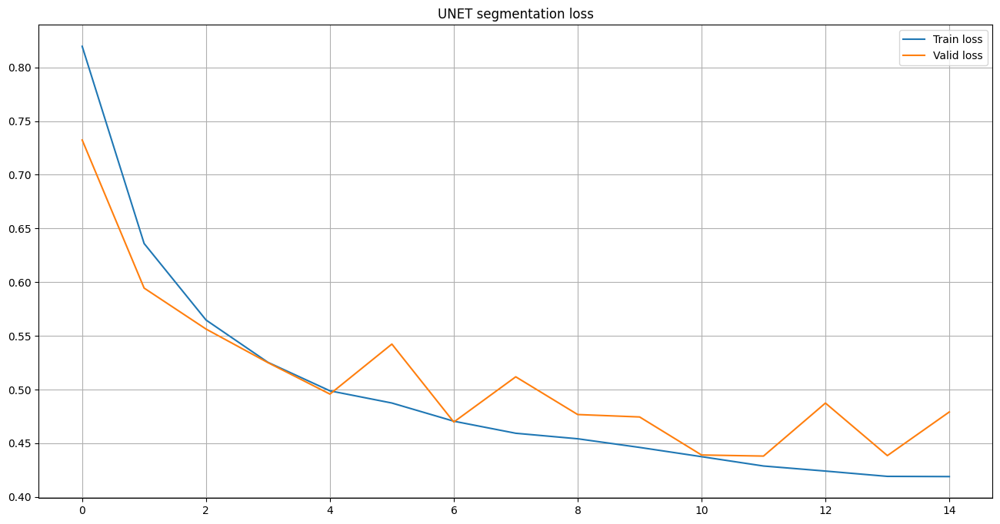

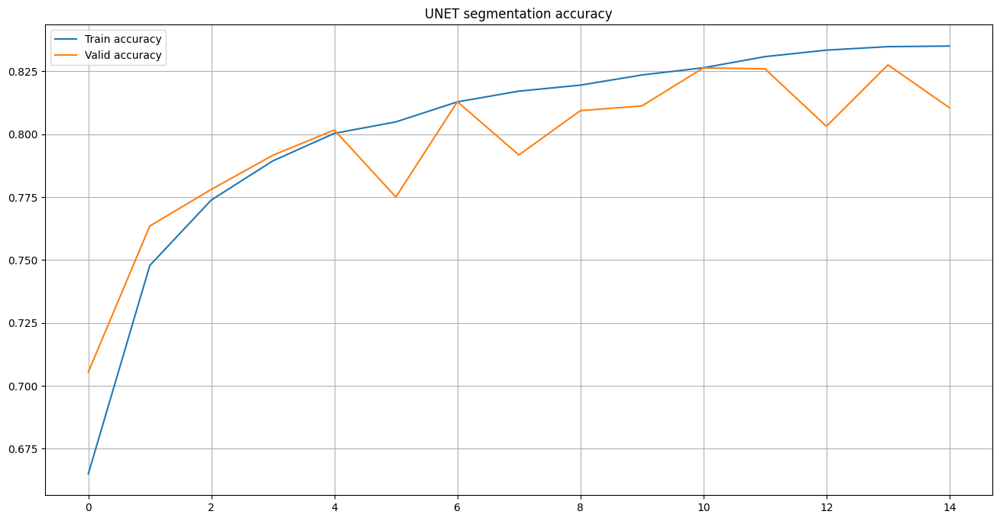

Train Loss: 0.4189, Train Accuracy: 0.8351
Valid Loss: 0.4791, Valid Accuracy: 0.8105

Визуализация предсказаний на валидационной выборке:


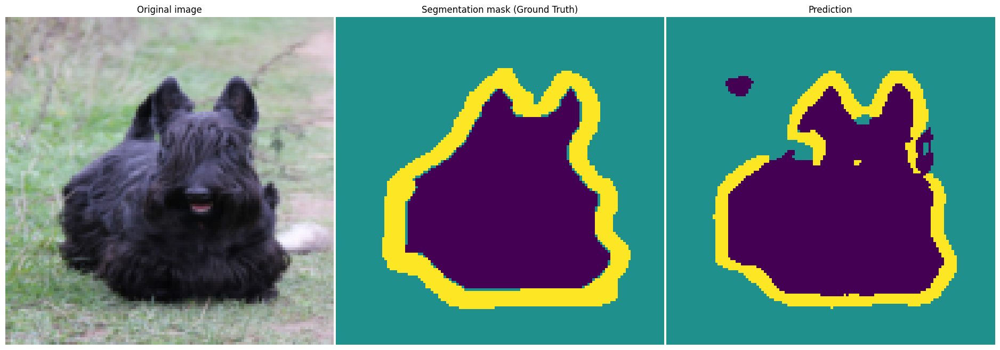

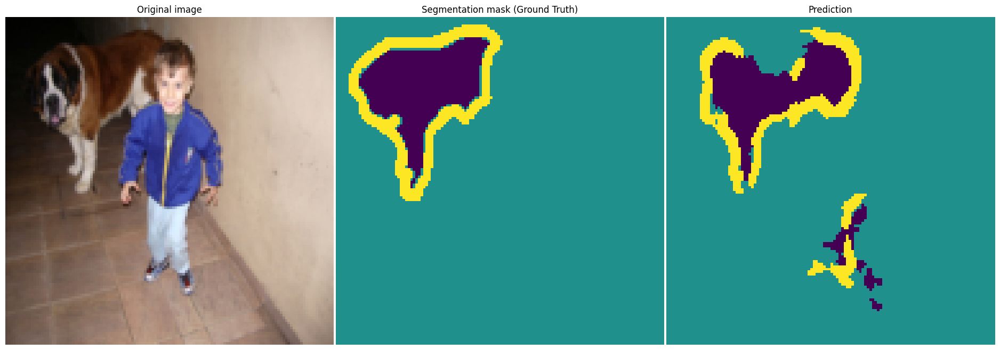

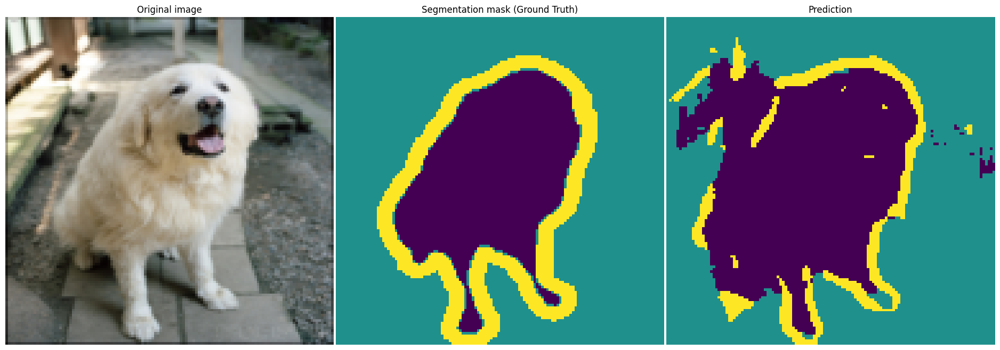

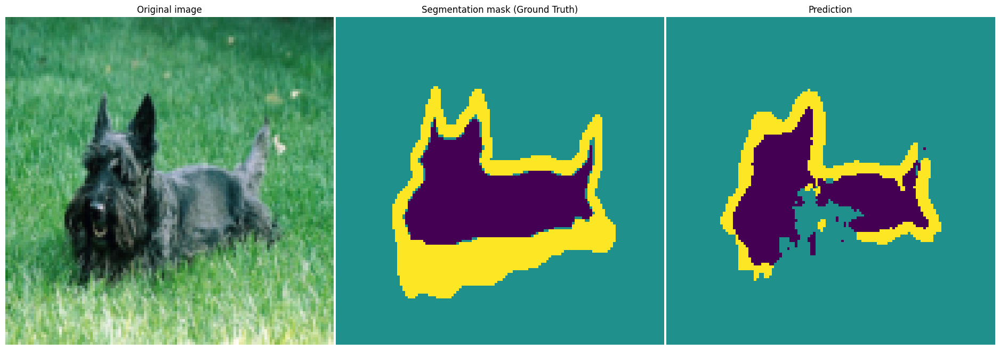

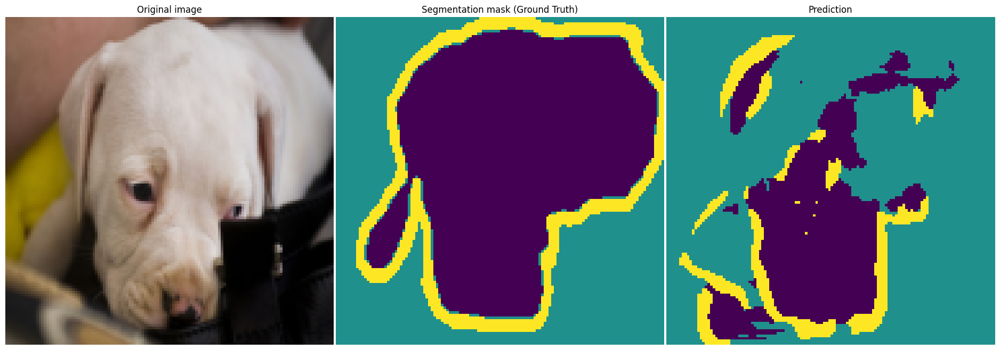

In [14]:
# 7. Запуск цикла обучения

print("\n--- Запуск обучения UNet для семантической сегментации ---")
# num_epochs (количество эпох): Гиперпараметр, определяющий, сколько раз модель
# будет проходить по всему обучающему датасету.
# Чем больше эпох, тем лучше модель может обучиться, но выше риск переобучения.
whole_train_valid_cycle(model, num_epochs=15, title='UNET segmentation')


--- Визуализация предсказаний на обучающей выборке после обучения ---


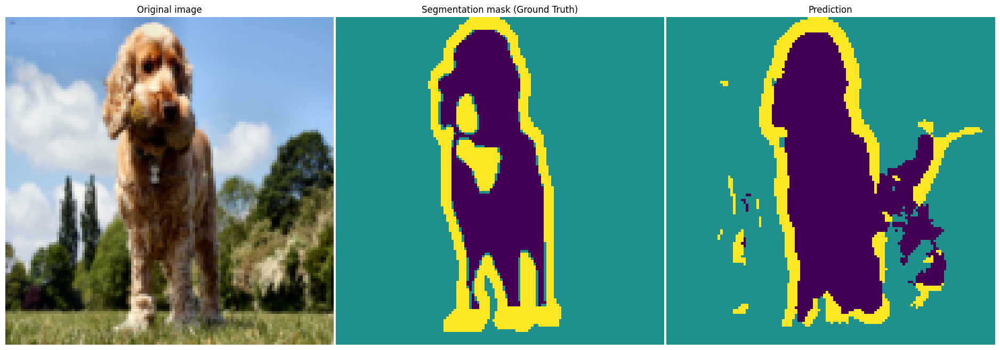

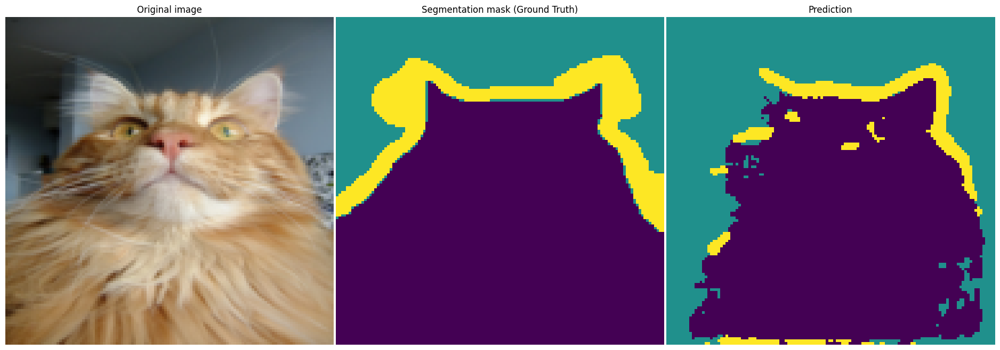

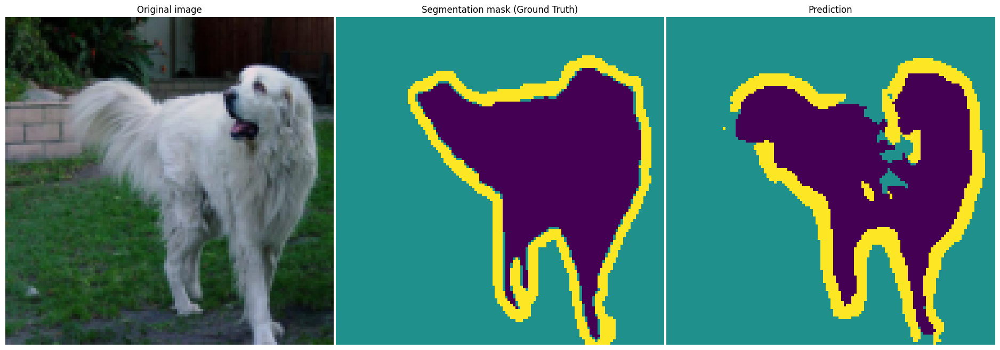

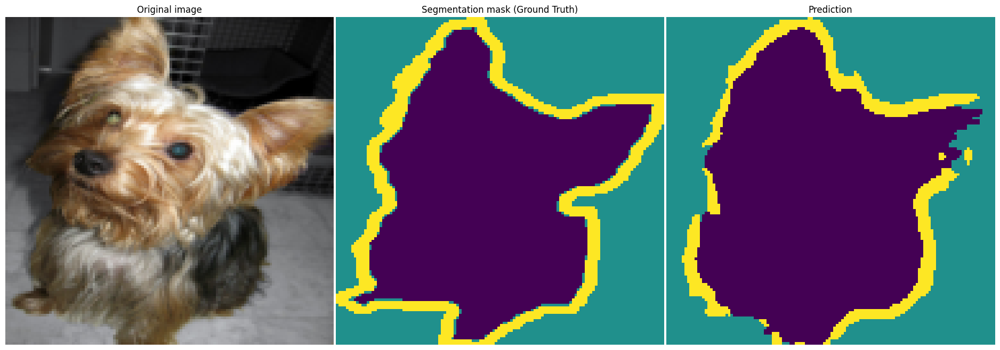

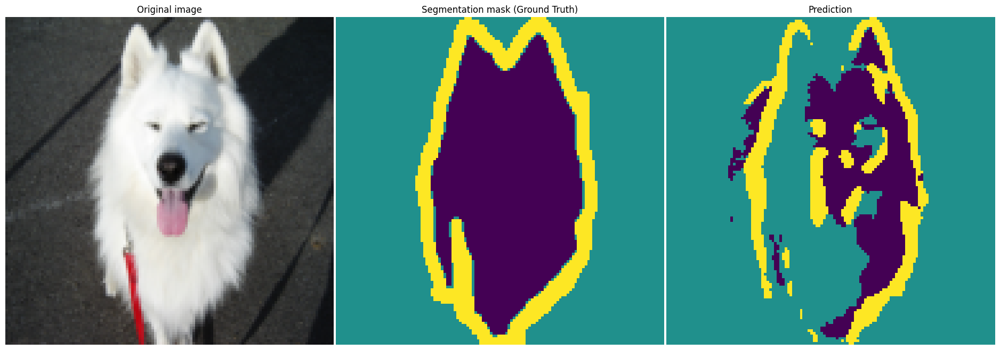


--- Выводы по семантической сегментации ---
Модель UNet успешно обучается и показывает неплохие результаты сегментации на датасете Oxford Pets.
На валидационной выборке предсказания достаточно четкие, но иногда с небольшими неточностями на границах.
Это связано с тем, что текущая UNet - небольшая (всего два блока down/up) и использует упрощенные методы апсемплинга (interpolate).
Для улучшения качества можно:
1. Увеличить base_channels (увеличить 'ширину' сети).
2. Добавить больше уровней сжатия/расширения (увеличить 'глубину' сети).
3. Использовать транспонированные свертки вместо интерполяции в декодировщике.
4. Провести более тщательный подбор гиперпараметров (learning rate, batch_size, оптимизатор).
5. Применить более сложные аугментации данных.


In [15]:
# 8. Визуализация результатов на обучающей выборке

print("\n--- Визуализация предсказаний на обучающей выборке после обучения ---")
# Визуализируем предсказания на случайном батче из обучающей выборки,
# чтобы увидеть, насколько хорошо модель справляется с данными, на которых обучалась.
visualize(model, next(iter(train_loader)))

print("\n--- Выводы по семантической сегментации ---")
print("Модель UNet успешно обучается и показывает неплохие результаты сегментации на датасете Oxford Pets.")
print("На валидационной выборке предсказания достаточно четкие, но иногда с небольшими неточностями на границах.")
print("Это связано с тем, что текущая UNet - небольшая (всего два блока down/up) и использует упрощенные методы апсемплинга (interpolate).")
print("Для улучшения качества можно:")
print("1. Увеличить base_channels (увеличить 'ширину' сети).")
print("2. Добавить больше уровней сжатия/расширения (увеличить 'глубину' сети).")
print("3. Использовать транспонированные свертки вместо интерполяции в декодировщике.")
print("4. Провести более тщательный подбор гиперпараметров (learning rate, batch_size, оптимизатор).")
print("5. Применить более сложные аугментации данных.")

# Детекция Объектов

Задача детекции объектов (Object Detection) сложнее семантической сегментации, так как она требует не только определения *что* за объект присутствует, но и его *точного местоположения* в виде ограничивающего прямоугольника (bounding box), а также *класса* этого объекта.

**Мотивация:**  
В отличие от семантической сегментации, которая даёт пиксельную маску, детекция объектов обычно возвращает список прямоугольников с метками классов и уровнем уверенности. Это полезно, когда:
* Нужно посчитать количество объектов.
* Важна общая локализация, а не идеальные границы.
* Системы видеонаблюдения: подсчёт людей, машин и других объектов.
* Автономные транспортные средства: определение других участников движения, светофоров и дорожных знаков.

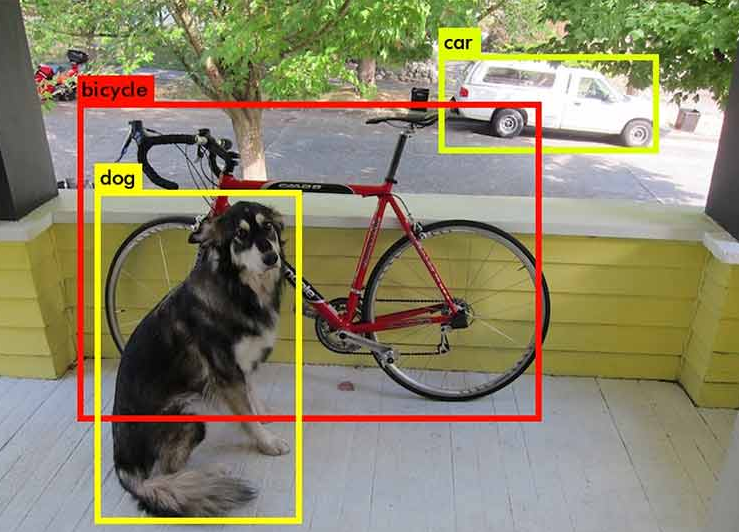  
_Пример детекции объектов на изображении._
)

### Постановка задачи

* **Входные данные:** Изображение.  
* **Выходные данные:** Список ограничивающих прямоугольников (bounding boxes), каждый из которых содержит:
  * Координаты прямоугольника (обычно xmin, ymin, xmax, ymax).  
  * Метку класса объекта внутри прямоугольника.  
  * Уровень уверенности (confidence score), с которой модель считает, что в этом прямоугольнике находится данный объект.  
* **Золотой стандарт:** Для обучения используются изображения с вручную размеченными ограничивающими прямоугольниками и соответствующими им классами.

**Примеры датасетов:**
* **PASCAL VOC (2007–2012):** 20 классов объектов, предоставляет bounding box аннотации. Используется часто для практики.  
* **COCO (Common Objects in Context):** Большой и популярный датасет (80 классов объектов), содержит аннотации для детекции, сегментации (Instance Segmentation) и ключевых точек.  
* **OXFORD-IIIT PETS:** Аннотации bounding box для животных.

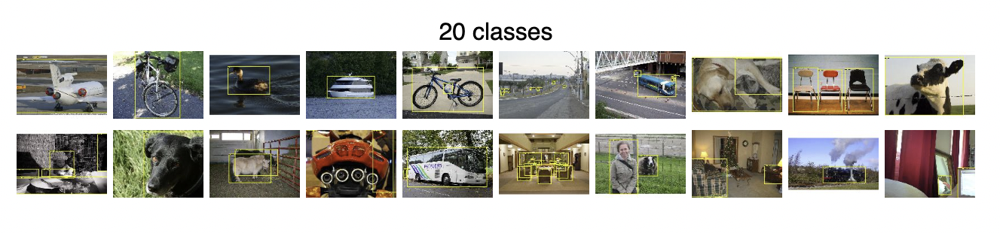  
_Пример изображений и аннотаций из PASCAL VOC. Показаны bounding boxes для различных объектов._



### Non-Maximum Suppression (NMS)

Модели детекции объектов часто выдают *множество* перекрывающихся ограничивающих прямоугольников для одного и того же объекта. Это нормально, так как нейронная сеть может быть "уверена" в нескольких похожих областях. Чтобы получить окончательный, наиболее точный набор предсказаний, используется алгоритм **Non-Maximum Suppression (NMS)**, что переводится как "подавление немаксимальных значений".

**Принцип работы NMS:**

1. **Для каждого класса отдельно:** NMS применяется независимо для каждого класса объектов. Это означает, что перекрывающиеся прямоугольники разных классов не будут подавляться друг другом.  
2. **Сортировка по уверенности:** Все предсказанные прямоугольники для данного класса сортируются по убыванию их уверенности (confidence score).  
3. **Итеративное подавление:**  
   * Выбирается прямоугольник с самой высокой уверенностью. Он добавляется в список окончательных предсказаний.  
   * Все остальные прямоугольники, которые **значительно перекрываются** с выбранным прямоугольником (т.е. имеют Intersection over Union (IoU) выше определённого порога), удаляются из рассмотрения.  
   * Процесс повторяется с оставшимися прямоугольниками, пока не останется ни одного прямоугольника для рассмотрения или пока все оставшиеся не будут иметь низкую уверенность / не будут существенно перекрываться.

**Гиперпараметр: порог IoU для NMS:**

* **IoU_threshold:** значение (обычно от 0.3 до 0.7), определяющее, когда два прямоугольника считаются "сильно перекрывающимися".  
* **Высокий порог:** оставляет больше прямоугольников, может привести к дубликатам.  
* **Низкий порог:** удаляет больше прямоугольников, может пропустить настоящие объекты, если они находятся близко друг к другу.  

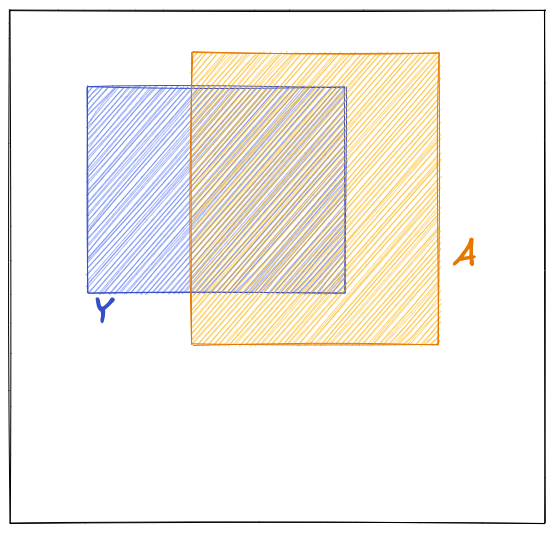  
_Мера Жаккара (IoU) для двух прямоугольников: область пересечения делится на область объединения._

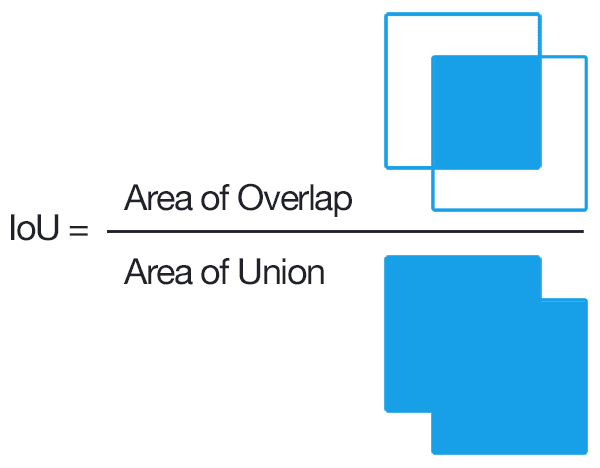  
**Как работает NMS:**

1. Выбираем прямоугольник с наибольшей уверенностью.  
2. Удаляем все перекрывающиеся с ним прямоугольники, если `IoU > порога`.  
3. Повторяем, пока не останется уверенных предсказаний.

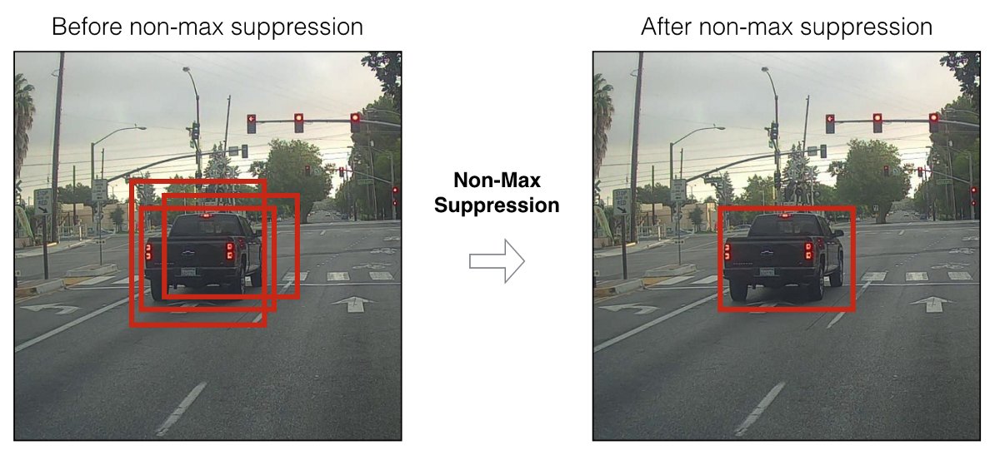  
_Пример применения NMS: множество исходных предсказаний (слева) сводится к одному наиболее уверенномy прямоугольнику (справа)._
_

### Метрики качества для детекции объектов

Оценка моделей детекции объектов сложнее, чем для классификации или сегментации, так как нужно учитывать *как* правильность класса, *так и* точность локализации.

1. **Intersection Over Union (IoU) для оценки корректности:**
   * Как и в сегментации, IoU используется для измерения перекрытия между предсказанным прямоугольником и истинным (ground truth) прямоугольником.
   * **Определение "корректного предсказания":** Предсказанный прямоугольник считается *корректным*, если его IoU с *единственным* истинным прямоугольником (того же класса) **больше определенного порога** (например, 0.5 или 0.75), *и* класс предсказан правильно.

2. **Precision (Точность) и Recall (Полнота):**  
   Это фундаментальные метрики, адаптированные для детекции.
   * $$\text{Precision} = \dfrac{\text{True Positives (TP)}}{\text{True Positives (TP)} + \text{False Positives (FP)}}$$  
     **Precision** показывает, какая доля предсказанных моделью объектов *действительно* является правильной. Высокий Precision означает, что у модели мало ложных срабатываний.
   * $$\text{Recall} = \dfrac{\text{True Positives (TP)}}{\text{True Positives (TP)} + \text{False Negatives (FN)}}$$  
     **Recall** показывает, какая доля *всех настоящих* объектов на изображении была обнаружена моделью. Высокий Recall означает, что модель пропускает мало настоящих объектов.

   **Как определяются TP, FP, FN в детекции:**
   * **True Positive (TP):** Модель правильно обнаружила объект. Это происходит, если:
     1. Предсказанный прямоугольник имеет IoU с истинным прямоугольником **выше порога** (например, 0.5).
     2. Предсказанный класс **совпадает** с истинным классом.
     3. Этот истинный прямоугольник ещё не был сопоставлен с другим (более уверенным) предсказанием.
   * **False Positive (FP):** Модель предсказала объект некорректно или предсказала объект, которого нет. Это происходит, если:
     1. Предсказанный прямоугольник имеет IoU с *любым* истинным прямоугольником **ниже порога** (например, 0.5).
     2. Предсказанный класс **не совпадает** с истинным классом (даже если IoU высок).
     3. Несколько предсказаний соответствуют одному и тому же истинному объекту (только первое засчитывается как TP, остальные — как FP).
   * **False Negative (FN):** Модель пропустила существующий объект. Это происходит, если:
     1. Истинный объект присутствует на изображении, но модель **не сделала ни одного предсказания**, которое бы удовлетворяло условиям TP (т.е. не было предсказания того же класса с IoU выше порога).

   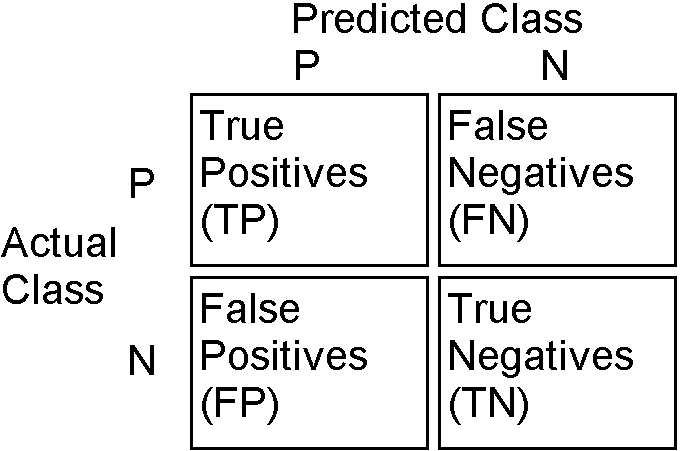  
   *Визуализация TP, FP, FN для детекции. Здесь зелёные рамки — TP, красные — FP, пунктирные синие — FN.*

3. **Precision-Recall Curve (PR-кривая), Average Precision (AP) и mean Average Precision (mAP):**
   * Precision и Recall зависят от порога уверенности (confidence threshold), который мы используем для отбора предсказаний. Чтобы получить одну метрику, независимую от этого порога, строится **PR-кривая**.
   * **PR-кривая:** график зависимости Precision от Recall при изменении порога уверенности. Чем выше кривая, тем лучше модель.
   * **Average Precision (AP):** площадь под PR-кривой для *одного конкретного класса*. Значение AP находится в диапазоне от 0 до 1. Высокое AP означает, что модель имеет как высокую точность, так и высокую полноту для этого класса.
     * В некоторых задачах AP может рассчитываться как среднее значение Precision в 11 или 101 точках Recall, чтобы сделать оценку более стабильной.
   * **mean Average Precision (mAP):** среднее значение AP по *всем классам* объектов. Это наиболее распространённая и всеобъемлющая метрика для оценки работы детектора.

   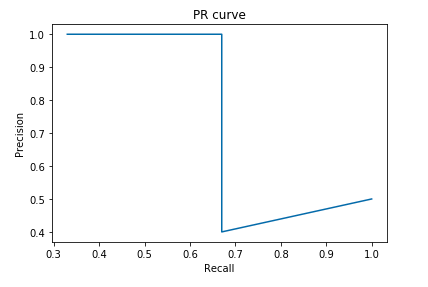  
   *Пример PR-кривой.*

   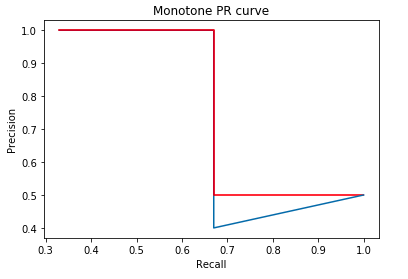  
   *Ось Precision vs Recall — визуализация расчёта площади под кривой.*

   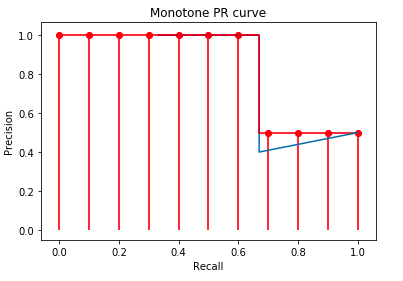  
   *Иллюстрации разных подходов к оценке AP: интегрирование под кривой и усреднение по фиксированным точкам Recall.*

**Важные пороги IoU:**
* В старых работах часто использовался порог IoU = 0.5 (обозначается как `AP@0.5`).
* В современных соревнованиях (например, COCO) используются более строгие и информативные метрики — усреднение AP по нескольким порогам IoU, например от 0.5 до 0.95 с шагом 0.05 (`mAP@[0.5:0.95]`).

## 4. Архитектуры нейронных сетей для детекции объектов

Модели детекции объектов можно разделить на два основных типа:

1.  **Two-shot (двухэтапные) детекторы:** Сначала генерируют набор "кандидатов" (регионов, где могут быть объекты), затем классифицируют эти кандидаты. Обычно более точные, но медленные. Примеры: R-CNN, Fast R-CNN, Faster R-CNN.
2.  **One-shot (одноэтапные) детекторы:** Одновременно предсказывают ограничивающие прямоугольники и классы объектов за один проход нейронной сети. Обычно быстрее, но могут быть менее точными. Примеры: YOLO, SSD, RetinaNet.

### Two-shot detection

**Общая идея:**

1.  **Этап предложения регионов (Region Proposal):** Найти на изображении все потенциальные области, которые могут содержать объект. Модель генерирует большое количество прямоугольников-кандидатов.
2.  **Этап классификации и регрессии (Classification and Bounding Box Regression):** Для каждого предложенного региона извлечь признаки и затем классифицировать его (есть объект/нет объекта, если есть, то какой класс) и уточнить координаты ограничивающего прямоугольника.

#### R-CNN (Regions with Convolutional Neural Networks)

[Оригинальная статья: Rich feature hierarchies for accurate object detection and semantic segmentation (2013)](https://arxiv.org/abs/1311.2524)

Это была одна из первых работ, успешно применивших глубокие сверточные сети для задачи детекции объектов.

**Принцип работы:**

1. **Генерация региональных предложений (Region Proposals):**  
   Используется классический алгоритм компьютерного зрения **Selective Search** для генерации около 2000 прямоугольников-кандидатов на изображении. Selective Search анализирует изображение и группирует похожие пиксели в области, которые могут быть объектами.  

   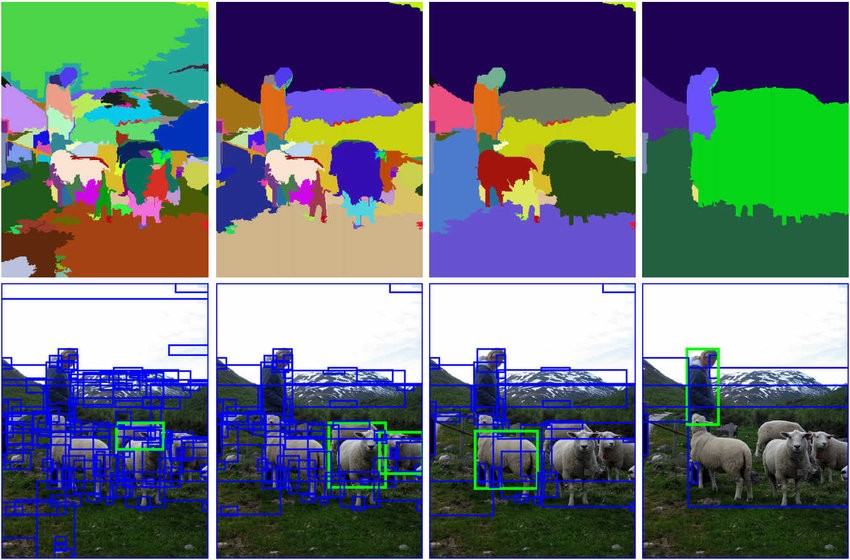  
   _Пример работы Selective Search: нахождение регионов-кандидатов._

2. **Извлечение признаков с помощью CNN:**  
   Каждый из этих 2000 предложенных регионов изменяется до фиксированного размера (например, 227x227) и подается на вход отдельной сверточной нейронной сети (например, AlexNet). CNN извлекает высокоуровневые признаки (вектор из 4096 чисел с последнего полносвязного слоя).

3. **Классификация с помощью SVM:**  
   Для каждого вектора признаков обученный классификатор **Support Vector Machine (SVM)** (обученный по принципу "один против всех" для каждого класса) предсказывает класс объекта в этом регионе.

4. **Уточнение bounding box:**  
   Отдельный линейный регрессор обучается для каждого класса, чтобы скорректировать координаты предсказанного прямоугольника и сделать его более точным.

   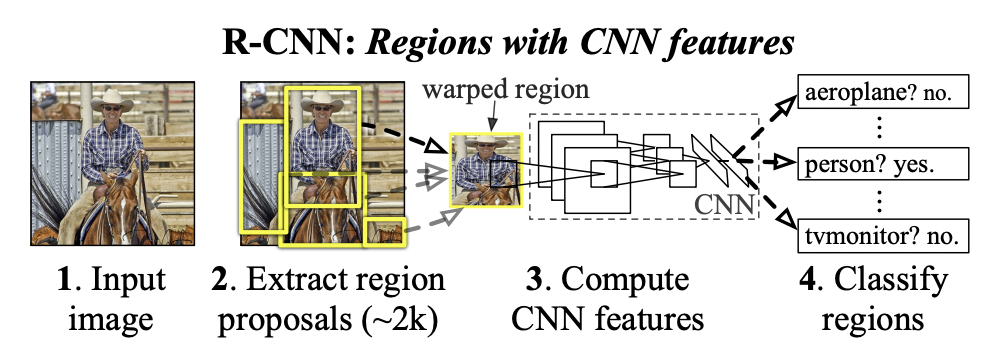

   _Схема работы R-CNN: 1. Генерация предложений. 2. Извлечение признаков CNN. 3. Классификация SVM._

**Проблемы R-CNN:**

* **Не End-to-End обучение:** Модель состоит из нескольких независимых компонентов (Selective Search, CNN, SVM, регрессор), которые обучаются отдельно. Это делает процесс сложным и неоптимальным.  
* **Чрезвычайно медленная скорость:** Каждый из 2000 регионов проходит через отдельную CNN, что означает 2000 проходов через сеть для одного изображения — десятки секунд на картинку.  
* **Высокие требования к памяти:** Хранение признаков для 2000 регионов для обучения SVM требует большого объёма памяти.  
* **Использование "классического CV":** Selective Search — эвристический алгоритм из классического компьютерного зрения, не обучаемый вместе с нейросетью, что ограничивает его адаптивность.
.

#### Fast R-CNN

[Оригинальная статья: Fast R-CNN (2015)](https://arxiv.org/abs/1504.0808)

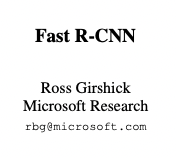  
_Fast R-CNN значительно ускорила R-CNN, решив проблему многократного прохода через CNN._

**Ключевая идея:**  
Выполнять сверточную сеть *только один раз* для всего изображения, а затем извлекать признаки для всех предложенных регионов из общей карты признаков.

**Принцип работы:**

1. **Однократный проход CNN:**  
   Исходное изображение подается на вход CNN *один раз* для извлечения общей карты признаков (`feature map`).

2. **Генерация региональных предложений:**  
   По-прежнему используется **Selective Search** (или аналогичный метод) для получения предложений регионов.

3. **ROI Pooling Layer (Region of Interest Pooling):**  
   Это ключевое нововведение. Для каждого предложенного региона (с координатами на исходном изображении) ROI Pooling слой определяет соответствующую область на общей карте признаков. Затем он преобразует эту область в вектор признаков *фиксированного размера*, независимо от изначального размера региона. Это достигается путем деления области на сетку фиксированного размера и применения `max pooling` в каждой ячейке.  
   * **Простыми словами:** Представьте, что вы сделали "фотографию" всего изображения. Вместо того чтобы "перефотографировать" каждую область отдельно (как в R-CNN), вы просто "вырезаете" нужные области с готовой карты признаков и масштабируете их до нужного размера для классификатора.

4. **Совместная классификация и регрессия:**  
   Извлеченные ROI Pooling признаки подаются на два выходных полносвязных слоя:
   * Один слой для **классификации** (Softmax для вероятностей классов).
   * Второй слой для **регрессии** (уточнение координат bounding box).  
   Эти две задачи обучаются **совместно** в одной модели.

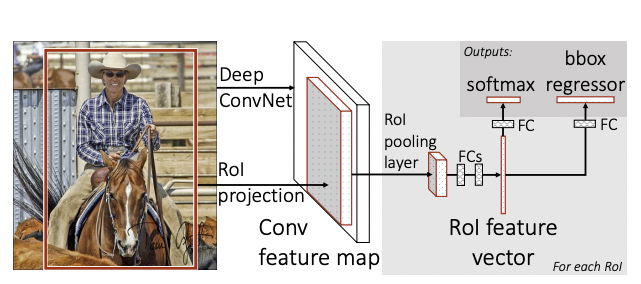  
_Схема Fast R-CNN: CNN применяется один раз, затем ROI Pooling извлекает признаки для фиксированного размера._

**Преимущества Fast R-CNN:**

* **Значительное ускорение обучения и инференса:** CNN применяется всего один раз на изображение.
* **End-to-End обучение (частично):** Теперь CNN, классификатор и регрессор обучаются совместно, что улучшает качество.
* **Улучшенная точность:** Совместное обучение приводит к лучшим результатам.

**Оставшиеся проблемы Fast R-CNN:**

* **Боттлнек: Генерация региональных предложений:** Selective Search по-прежнему остаётся внешним, не обучаемым компонентом и является самым медленным этапом в Fast R-CNN. Это "бутылочное горлышко" ограничивает общую скорость работы модели.

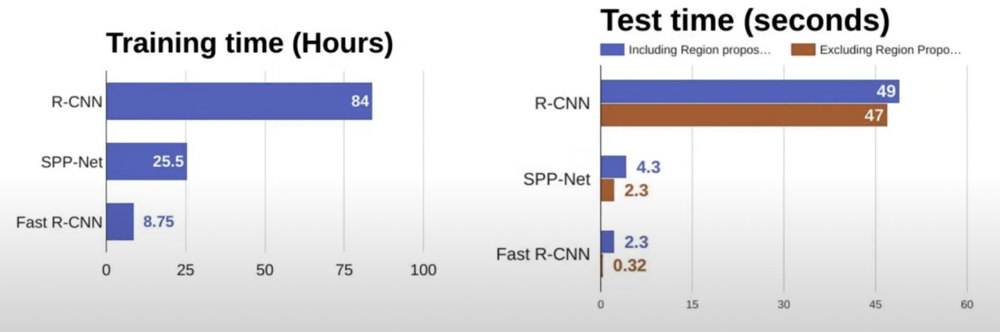

#### Faster R-CNN

[Оригинальная статья: Faster R-CNN: Towards Real-Time Object Detection with Region Proposal Networks (2015)](https://arxiv.org/abs/1506.0149)

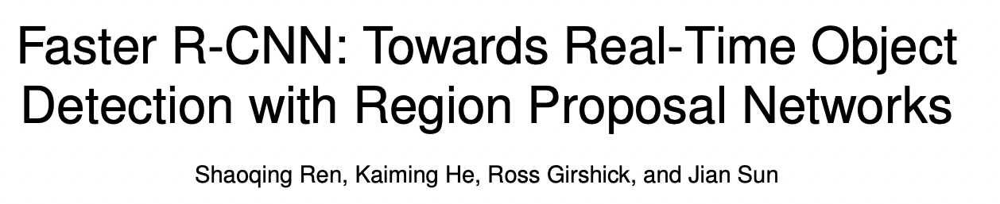  
_Faster R-CNN решила последнюю проблему, превратив этап генерации региональных предложений в обучаемую нейронную сеть, тем самым сделав всю систему **полностью End-to-End**._

**Ключевое нововведение: Region Proposal Network (RPN)**

* **RPN** — небольшая сверточная сеть, которая работает поверх карты признаков, полученной от основной CNN (backbone), и предсказывает **региональные предложения** (прямоугольники-кандидаты) и их "объективность" (вероятность, что в прямоугольнике есть объект).
* **Anchor Boxes:** RPN использует заранее определённые прямоугольники различных размеров и соотношений сторон, расположенные по всему изображению. RPN предсказывает, насколько каждый anchor box должен быть скорректирован (сдвиг и масштабирование), а также вероятность того, что в скорректированном прямоугольнике есть объект.
  * **Пример:** Для каждой ячейки на карте признаков RPN генерирует, например, 9 anchor boxes (3 размера × 3 соотношения сторон). Для каждого anchor box RPN предсказывает:
    * 2 значения: вероятность фона и вероятность объекта.
    * 4 значения: смещение (dx, dy, dw, dh) для корректировки размера и положения.

**Принцип работы Faster R-CNN:**

1. **Backbone CNN (Feature Extractor):**  
   Изображение проходит через сверточную сеть (например, VGG, ResNet, MobileNet) для извлечения карты признаков.

2. **Region Proposal Network (RPN):**  
   * RPN работает на карте признаков, предсказывая региональные предложения.  
   * Выдает два набора результатов: "объективность" каждого anchor box (объект / фон) и корректировки координат.  
   * Применяется NMS к выходным данным RPN, чтобы оставить, например, 2000 наиболее уверенных предложений.

3. **ROI Pooling (или ROI Align):**  
   Для каждого предложенного RPN региона извлекается вектор признаков фиксированного размера из общей карты признаков.

4. **Fast R-CNN Head:**  
   Эти признаки подаются на Fast R-CNN head для:
   * классификации объекта (к какому классу относится),  
   * уточнения координат bounding box.

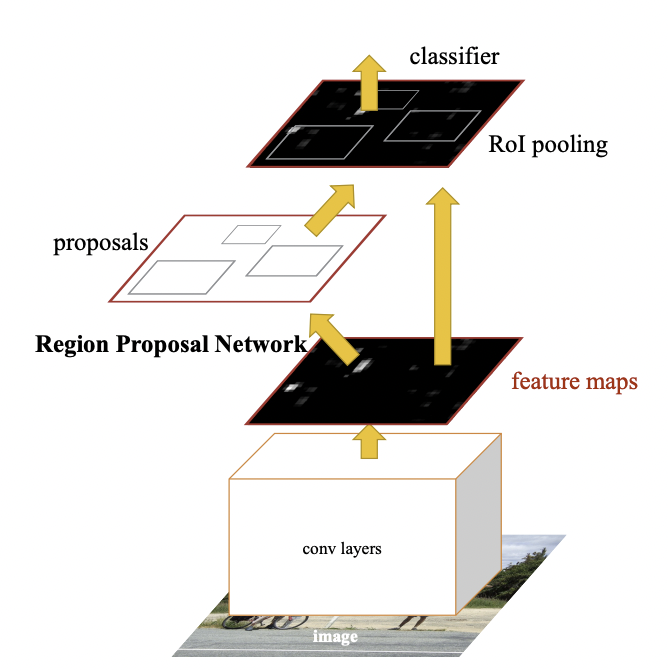  
_Схема Faster R-CNN. Ключевое отличие: Region Proposal Network (RPN) генерирует предложения вместо Selective Search._

**Функция потерь (совместное обучение):**  
Вся модель (backbone, RPN, классификатор, регрессор) обучается end-to-end на сумму четырёх функций потерь:
1. Потеря классификации объективности RPN (есть объект / фон для каждого anchor box).  
2. Потеря регрессии bounding box RPN (корректировка координат anchor box).  
3. Потеря классификации Fast R-CNN (класс объекта для каждого ROI).  
4. Потеря регрессии bounding box Fast R-CNN (финальная корректировка координат ROI).

**Преимущества Faster R-CNN:**

* **Полностью End-to-End:** все компоненты обучаются совместно, что ведёт к оптимальной работе.  
* **Значительное ускорение:** RPN гораздо быстрее Selective Search, что позволяет приближаться к скорости реального времени.  
* **Высокая точность:** сохраняется высокая точность, характерная для двухэтапных детекторов.

**Проблемы Faster R-CNN:**

* **Сложность обучения:** модель сложна, с четырьмя функциями потерь и множеством компонентов. Обучение с нуля может быть нестабильным и требовать больших ресурсов; часто используют **transfer learning** с предобученной модели (например, ImageNet или COCO).  
* **Относительная скорость:** хотя быстрее предшественников, Faster R-CNN всё ещё уступает одноэтапным детекторам.

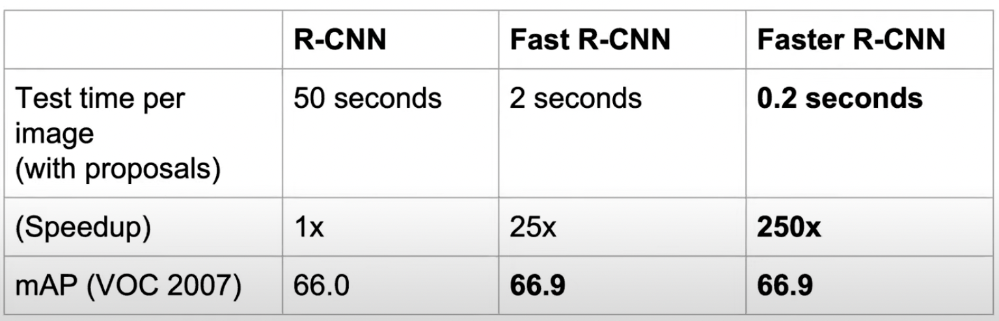  
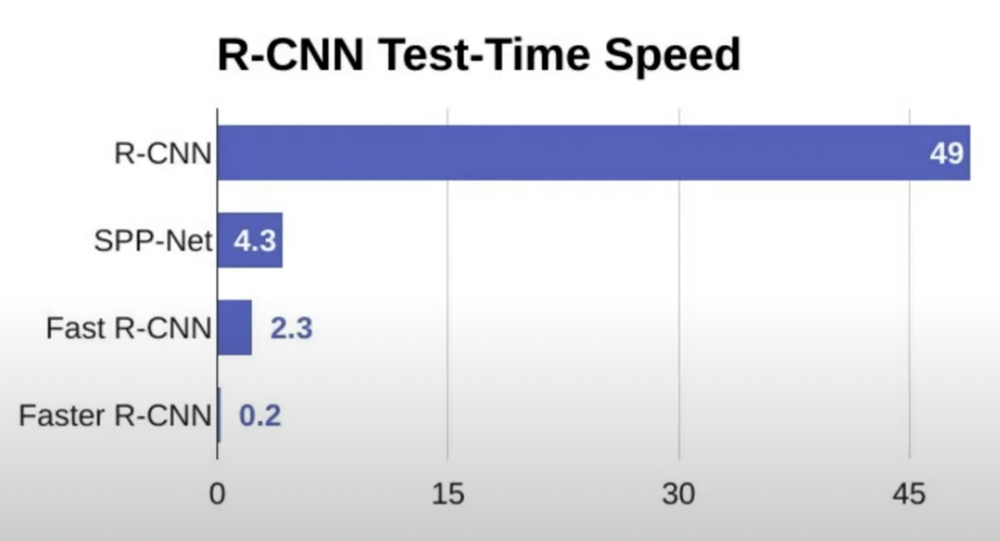  

Сравнение mAP и скорости: Faster R-CNN.


### One-shot detection

Одноэтапные детекторы, как следует из названия, выполняют всю задачу детекции за один проход нейронной сети, предсказывая bounding boxes и классы объектов напрямую из входного изображения. Это делает их значительно быстрее.

#### YOLO (You Only Look Once)

[Оригинальная статья: You Only Look Once: Unified, Real-Time Object Detection (2015)](https://arxiv.org/abs/1506.0264)

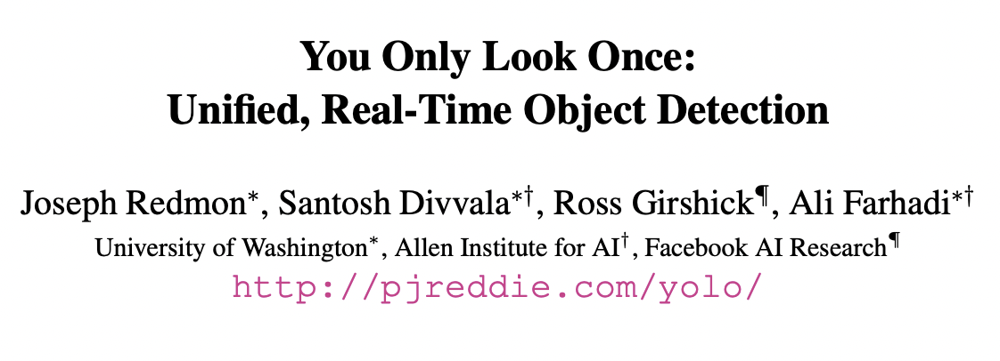  
_YOLO радикально изменил подход к детекции объектов, переформулировав её как одну задачу регрессии. Название "You Only Look Once" подчеркивает, что модель делает только один проход по изображению._

**Основная идея:**  
Разбить входное изображение на сетку (например, $S \times S$ ячеек) и для каждой ячейки предсказывать:
* Несколько ограничивающих прямоугольников (bounding boxes).  
* Уровень уверенности для каждого прямоугольника (насколько вероятно, что в нём есть объект).  
* Распределение вероятностей классов для объекта в этом прямоугольнике.

**Принцип работы:**

1. **Разбивка на сетку:**  
   Входное изображение делится на сетку размером $S \times S$ (например, 7x7).

2. **Предсказания для каждой ячейки сетки:**  
   Если центр объекта попадает в ячейку, она становится "ответственной" за предсказание объекта. Для каждой ячейки YOLO предсказывает:
   * **$B$ ограничивающих прямоугольников:**  
     Для каждого прямоугольника:
     * **Координаты:** $(x, y, w, h)$, где $(x, y)$ — центр прямоугольника относительно ячейки, а $w, h$ — ширина и высота относительно всего изображения.  
     * **Уверенность (Confidence Score):** $P(\text{Object}) \times \text{IoU}(\text{pred}, \text{truth})$. Если объекта нет, уверенность близка к нулю.
   * **$C$ вероятностей классов:** $P(\text{Class}_i \mid \text{Object})$ — условная вероятность класса объекта, предсказываемая один раз для каждой ячейки, независимо от количества bounding boxes.

3. **Выходной тензор:**  
   Все предсказания объединяются в один тензор размерности $S \times S \times (B \times 5 + C)$.  
   * Пример: сетка 7x7, 2 bounding boxes на ячейку, 20 классов → $7 \times 7 \times (2 \times 5 + 20) = 7 \times 7 \times 30$.  
   * Каждая ячейка имеет вектор длиной 30: первые $B \times 5$ элементов для bounding boxes и confidence score, следующие $C$ элементов — вероятности классов.

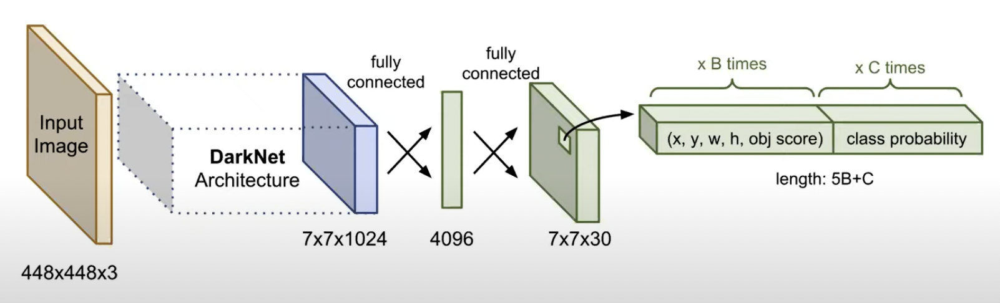  
_Схема работы YOLO: изображение разбивается на сетку, каждая ячейка предсказывает bounding boxes._

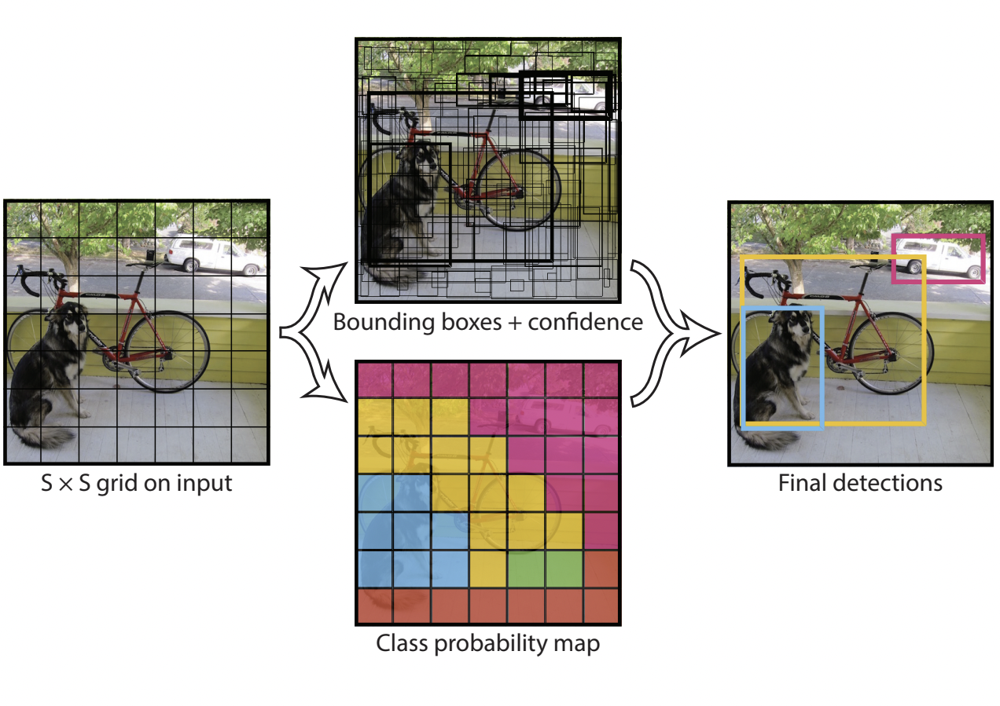  
_Пример выхода YOLO: каждая ячейка предсказывает bounding boxes с уверенностью и карту вероятностей классов._

**Преимущества YOLO:**

* **Очень высокая скорость:** до 150+ FPS для Fast YOLO.  
* **Глобальный контекст:** предсказывает bounding boxes с учётом всего изображения, что снижает количество ложных срабатываний.  
* **Простота архитектуры:** одна CNN для всей модели, упрощает обучение и развертывание.

**Недостатки YOLO:**

* **Меньшая точность по сравнению с двухэтапными методами:** фиксированная сетка ограничивает способность обнаруживать маленькие или скученные объекты.  
* **Проблемы с соотношением сторон:** трудности с объектами нестандартных форм.

YOLO постоянно развивается, и существуют многочисленные версии (YOLOv2, YOLOv3, YOLOv4, YOLOv5, YOLOR, YOLOv7, YOLOv8), которые значительно улучшают как скорость, так и точность.

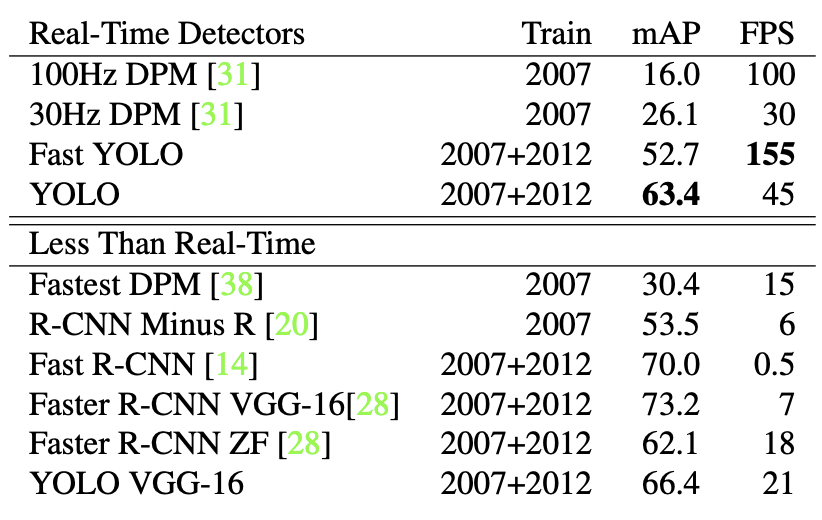


#### RetinaNet

[Оригинальная статья: Focal Loss for Dense Object Detection (2017)](https://arxiv.org/abs/1708.02002)

RetinaNet — это одноэтапный детектор, который достиг точности двухэтапных детекторов, значительно превзойдя их по скорости. Ключевое нововведение RetinaNet — это **Focal Loss**, которая решает проблему крайнего дисбаланса классов в одноэтапных детекторах (большинство предложенных мест — это фон). Focal Loss фокусирует обучение на "сложных" (hard) примерах, уменьшая вес "легких" (easy) примеров.

Мы не будем разбирать RetinaNet подробно в рамках этого вводного урока из-за ее сложности, но она является важным этапом в развитии one-shot детекторов.

## 5. Практическая реализация для детекции объектов

В этой части мы будем дообучать (fine-tune) предобученную модель Faster R-CNN на датасете PASCAL VOC. Использование предобученной модели значительно ускоряет обучение и позволяет достичь хороших результатов даже на относительно небольших датасетах.

In [20]:
#!g1.1
torch.cuda.empty_cache()

In [150]:
#pragma dataset init voc --size 5Gb
from torchvision.datasets import VOCDetection

dataset = VOCDetection('/home/jupyter/mnt/datasets/voc', download=True)

  0%|          | 0/1999639040 [00:00<?, ?it/s]

Background cell scheduled. Waiting for foreground cells to finish commits
Preparing c1.4 instance...
c1.4 instance is ready, running task...
Extracting /home/jupyter/mnt/datasets/voc/VOCtrainval_11-May-2012.tar to /home/jupyter/mnt/datasets/voc
Task is done, waiting for foreground cells to finish...
It's init dataset task. State result won't be merged.


In [21]:
#!g1.1
from torchvision.datasets import VOCDetection

dataset = VOCDetection('/home/jupyter/mnt/datasets/voc', image_set='train')

In [22]:
#!g1.1
len(dataset)

5717

In [23]:
#!g1.1
dataset[0]

(<PIL.Image.Image image mode=RGB size=500x442>,
 {'annotation': {'folder': 'VOC2012',
   'filename': '2008_000008.jpg',
   'source': {'database': 'The VOC2008 Database',
    'annotation': 'PASCAL VOC2008',
    'image': 'flickr'},
   'size': {'width': '500', 'height': '442', 'depth': '3'},
   'segmented': '0',
   'object': [{'name': 'horse',
     'pose': 'Left',
     'truncated': '0',
     'occluded': '1',
     'bndbox': {'xmin': '53', 'ymin': '87', 'xmax': '471', 'ymax': '420'},
     'difficult': '0'},
    {'name': 'person',
     'pose': 'Unspecified',
     'truncated': '1',
     'occluded': '0',
     'bndbox': {'xmin': '158', 'ymin': '44', 'xmax': '289', 'ymax': '167'},
     'difficult': '0'}]}})

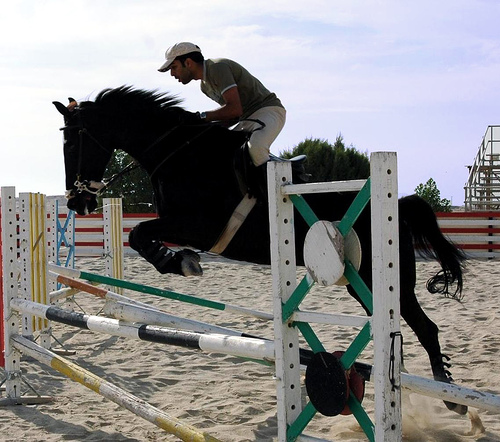

In [24]:
#!g1.1
dataset[0][0]

In [25]:
#!g1.1
target_names = []

for obj in dataset:
    target_names.extend([x['name'] for x in obj[1]['annotation']['object']])

target_names = list(set(target_names))

In [26]:
#!g1.1
target_names

['boat',
 'train',
 'cow',
 'bottle',
 'dog',
 'bicycle',
 'chair',
 'motorbike',
 'diningtable',
 'bird',
 'pottedplant',
 'sofa',
 'tvmonitor',
 'person',
 'horse',
 'cat',
 'car',
 'sheep',
 'aeroplane',
 'bus']

In [27]:
#!g1.1
target2idx = {name: i for i, name in enumerate(target_names)}
idx2target = {i: name for i, name in enumerate(target_names)}

target2idx, idx2target

({'boat': 0,
  'train': 1,
  'cow': 2,
  'bottle': 3,
  'dog': 4,
  'bicycle': 5,
  'chair': 6,
  'motorbike': 7,
  'diningtable': 8,
  'bird': 9,
  'pottedplant': 10,
  'sofa': 11,
  'tvmonitor': 12,
  'person': 13,
  'horse': 14,
  'cat': 15,
  'car': 16,
  'sheep': 17,
  'aeroplane': 18,
  'bus': 19},
 {0: 'boat',
  1: 'train',
  2: 'cow',
  3: 'bottle',
  4: 'dog',
  5: 'bicycle',
  6: 'chair',
  7: 'motorbike',
  8: 'diningtable',
  9: 'bird',
  10: 'pottedplant',
  11: 'sofa',
  12: 'tvmonitor',
  13: 'person',
  14: 'horse',
  15: 'cat',
  16: 'car',
  17: 'sheep',
  18: 'aeroplane',
  19: 'bus'})

In [28]:
#!g1.1
def target_transform(voc_target):
    target = {}
    
    target['boxes'] = torch.tensor(
        [
            [
                float(x['bndbox']['xmin']),
                float(x['bndbox']['ymin']),
                float(x['bndbox']['xmax']),
                float(x['bndbox']['ymax'])
            ] for x in voc_target['annotation']['object']
        ],
        dtype=torch.float32
    )
    target['labels'] = torch.tensor([target2idx[x['name']] for x in voc_target['annotation']['object']], dtype=torch.int64)
    
    return target

In [29]:
#!g1.1
target_transform(dataset[0][1])

{'boxes': tensor([[ 53.,  87., 471., 420.],
         [158.,  44., 289., 167.]]),
 'labels': tensor([14, 13])}

In [30]:
#!g1.1
from torchvision.utils import draw_bounding_boxes


def show(imgs):
    to_pil = T.ToPILImage()
    
    if not isinstance(imgs, list):
        imgs = [imgs]
    fix, axs = plt.subplots(ncols=len(imgs), squeeze=False, figsize=(16, 8))
    for i, img in enumerate(imgs):
        img = img.detach()
        img = to_pil(img)
        axs[0, i].imshow(np.asarray(img))
        axs[0, i].set(xticklabels=[], yticklabels=[], xticks=[], yticks=[])

def draw_boxes_single_image(image, boxes, labels):
    colors = ["red" for _ in boxes]

    show(draw_bounding_boxes(image, boxes, labels, colors=colors, width=5))

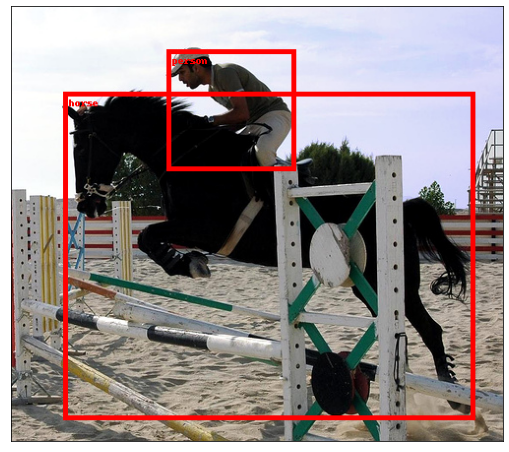

In [31]:
#!g1.1
draw_boxes_single_image(
    T.PILToTensor()(dataset[0][0]),
    target_transform(dataset[0][1])['boxes'],
    [idx2target[label.item()] for label in target_transform(dataset[0][1])['labels']]
)

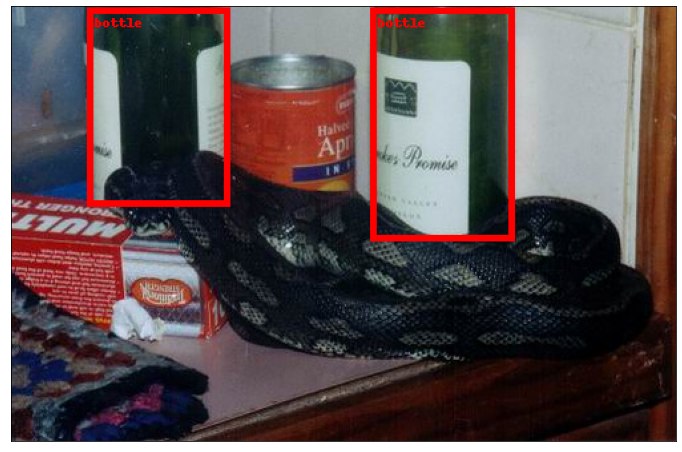

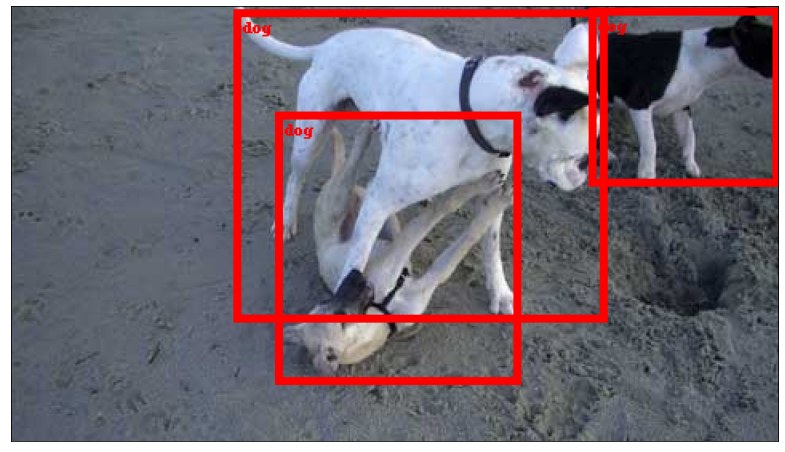

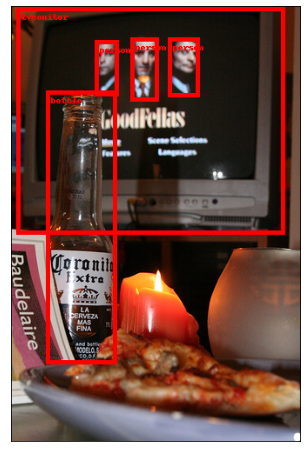

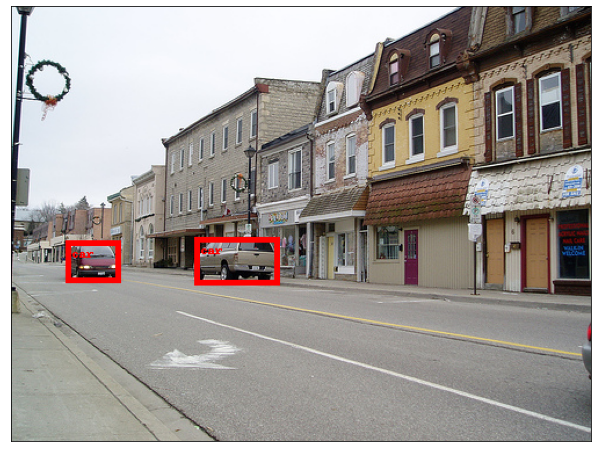

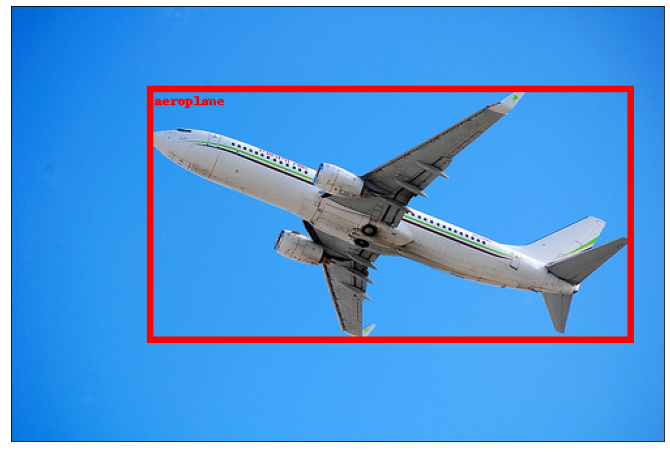

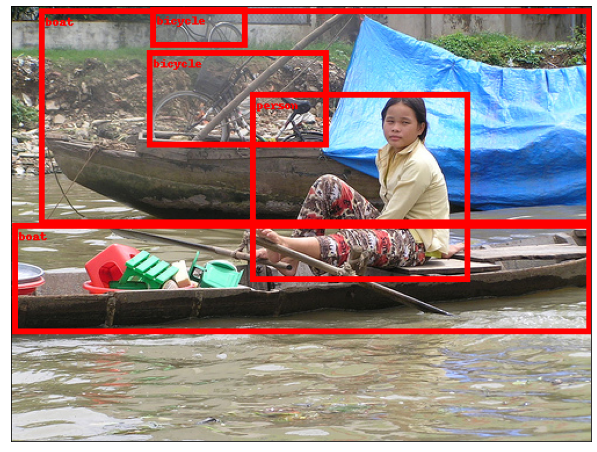

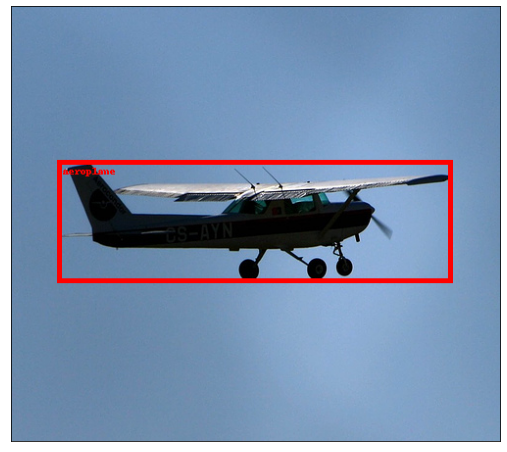

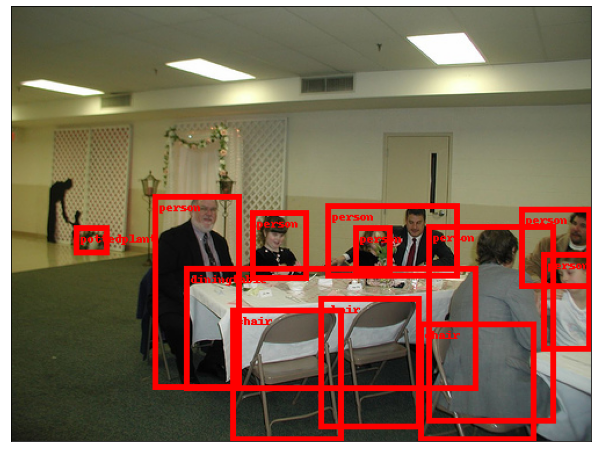

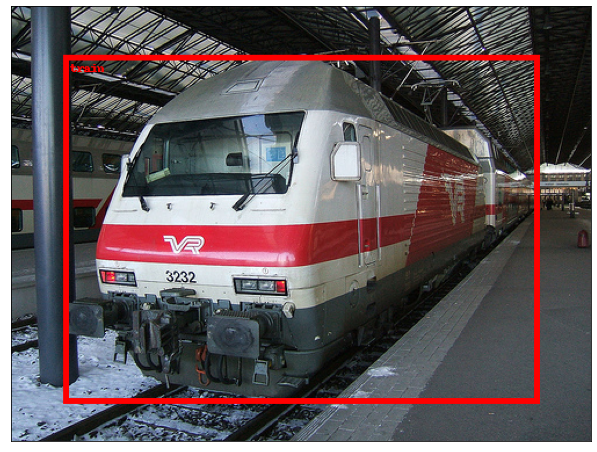

In [32]:
#!g1.1
for i in range(1, 10):
    draw_boxes_single_image(
        T.PILToTensor()(dataset[i][0]),
        target_transform(dataset[i][1])['boxes'],
        [idx2target[label.item()] for label in target_transform(dataset[i][1])['labels']]
    )

In [33]:
#!g1.1
def collate_fn(batch):
    return tuple(zip(*batch))

dataset_train = VOCDetection(
    '/home/jupyter/mnt/datasets/voc',
    image_set='train',
    transform=T.ToTensor(),
    target_transform=target_transform
)

dataset_test = VOCDetection(
    '/home/jupyter/mnt/datasets/voc',
    image_set='val',
    transform=T.ToTensor(),
    target_transform=target_transform
)

train_loader = DataLoader(dataset_train, batch_size=8, shuffle=True, num_workers=8, pin_memory=True, collate_fn=collate_fn)
valid_loader = DataLoader(dataset_test, batch_size=8, shuffle=False, num_workers=8, pin_memory=True, collate_fn=collate_fn)

In [103]:
#!g1.1
from torchvision.models.detection import fasterrcnn_mobilenet_v3_large_320_fpn
from torchvision.models.detection.faster_rcnn import FastRCNNPredictor


def get_detection_model():
    model = fasterrcnn_mobilenet_v3_large_320_fpn(pretrained=True)
    
    model.roi_heads.box_predictor = FastRCNNPredictor(1024, len(target_names))
    
    return model

In [104]:
#!g1.1
model = get_detection_model()

model

FasterRCNN(
  (transform): GeneralizedRCNNTransform(
      Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
      Resize(min_size=(320,), max_size=640, mode='bilinear')
  )
  (backbone): BackboneWithFPN(
    (body): IntermediateLayerGetter(
      (0): ConvNormActivation(
        (0): Conv2d(3, 16, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1), bias=False)
        (1): FrozenBatchNorm2d(16, eps=1e-05)
        (2): Hardswish()
      )
      (1): InvertedResidual(
        (block): Sequential(
          (0): ConvNormActivation(
            (0): Conv2d(16, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), groups=16, bias=False)
            (1): FrozenBatchNorm2d(16, eps=1e-05)
            (2): ReLU(inplace=True)
          )
          (1): ConvNormActivation(
            (0): Conv2d(16, 16, kernel_size=(1, 1), stride=(1, 1), bias=False)
            (1): FrozenBatchNorm2d(16, eps=1e-05)
          )
        )
      )
      (2): InvertedResidual(
        (block): Sequen

In [105]:
#!g1.1
%pip install torchmetrics

Defaulting to user installation because normal site-packages is not writeable


In [128]:
#!g1.1
from torchmetrics.detection.mean_ap import MeanAveragePrecision
from torchvision.ops import batched_nms


def intersection_over_union(dt_bbox, gt_bbox):
    int_x0 = max(dt_bbox[0], gt_bbox[0])
    int_y0 = max(dt_bbox[1], gt_bbox[1])

    int_x1 = min(dt_bbox[2], gt_bbox[2])
    int_y1 = min(dt_bbox[3], gt_bbox[3])

    intersection = max(int_x1 - int_x0, 0) * max(int_y1 - int_y0, 0)
    dt_area = (dt_bbox[2] - dt_bbox[0]) * (dt_bbox[3] - dt_bbox[1])
    gt_area = (gt_bbox[2] - gt_bbox[0]) * (gt_bbox[3] - gt_bbox[1])

    return intersection / (dt_area + gt_area - intersection)


def apply_nms(orig_prediction, iou_thresh=0.3):
    
    keep = batched_nms(orig_prediction['boxes'], orig_prediction['scores'], orig_prediction['labels'], iou_thresh)

    final_prediction = orig_prediction

    final_prediction['boxes'] = final_prediction['boxes'][keep]
    final_prediction['scores'] = final_prediction['scores'][keep]
    final_prediction['labels'] = final_prediction['labels'][keep]
    
    return final_prediction


@torch.inference_mode()
def visualize(model, batch):
    model.eval()
    
    to_pil = T.ToPILImage()
    to_tensor = T.PILToTensor()

    xs, ys = batch

    for i, (x, y) in enumerate(zip(xs, ys)):
        prediction = {k: v.to(device) for k, v in model([x.to(device)])[0].items()}

        prediction = apply_nms(prediction)

        x = to_tensor(to_pil(x.cpu()))

        true_boxes = draw_bounding_boxes(x, boxes=y['boxes'], labels=[idx2target[label.item()] for label in y['labels']], width=5, colors='red')
        predicted_boxes = draw_bounding_boxes(x, boxes=prediction['boxes'], labels=[idx2target[label.item()] for label in prediction['labels']], width=5, colors='red')
        
        fig, ax = plt.subplots(1, 2, figsize=(20, 10), facecolor='white')

        ax[0].imshow(to_pil(true_boxes))
        ax[1].imshow(to_pil(predicted_boxes))

        ax[0].axis('off')
        ax[1].axis('off')

        ax[0].set_title('Target boxes')
        ax[1].set_title('Predicted boxes')

        plt.subplots_adjust(wspace=0, hspace=0.1)
        plt.show()

        if i >= 9:
            break

In [129]:
#!g1.1
def train(model):
    model.train()

    for x, y in tqdm(train_loader, desc='Train'):
        x = list(_.to(device).float() for _ in x)
        y = [{k: v.to(device) for k, v in t.items()} for t in y]

        optimizer.zero_grad()

        output = model(x, y)
        
        loss_sum = sum(loss for loss in output.values())

        loss_sum.backward()

        optimizer.step()

In [130]:
#!g1.1
@torch.inference_mode()
def evaluate(model, loader):
    model.eval()
    
    metric = MeanAveragePrecision()

    for x, y in tqdm(loader, desc='Evaluation'):
        x = list(_.to(device).float() for _ in x)

        output = model(x)
        
        output = [{k: v.cpu() for k, v in t.items()} for t in output]

        metric.update(output, y)

    return metric.compute()['map']

In [131]:
#!g1.1

def plot_stats(
    train_map: list[float],
    valid_map: list[float],
    title: str
):
    plt.figure(figsize=(16, 8))

    plt.title(title + ' mAP')
    
    plt.plot(train_map, label='Train mAP')
    plt.plot(valid_map, label='Valid mAP')
    plt.legend()
    plt.grid()

    plt.show()

In [132]:
#!g1.1
def whole_train_valid_cycle(model, num_epochs, title):
    batch = next(iter(valid_loader))

    for epoch in range(num_epochs):
        train(model)

        clear_output()

        visualize(model, batch)

In [133]:
#!g1.1
model = get_detection_model().to(device)

optimizer = Adam([p for p in model.parameters() if p.requires_grad], lr=1e-4)

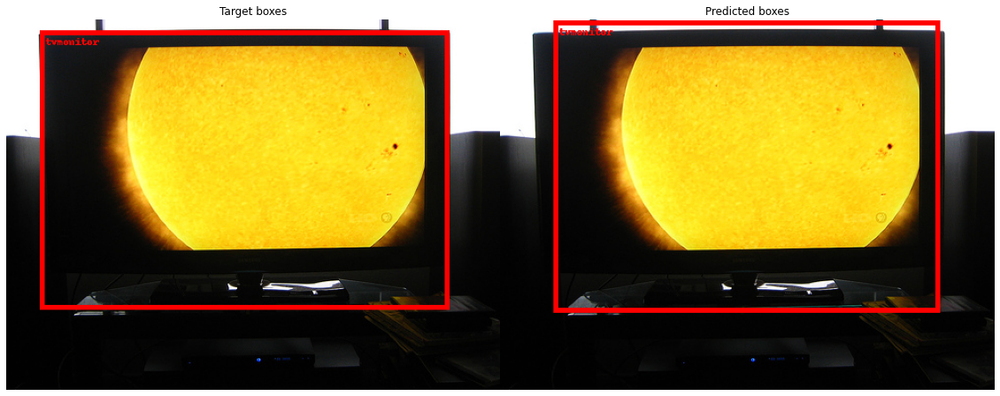

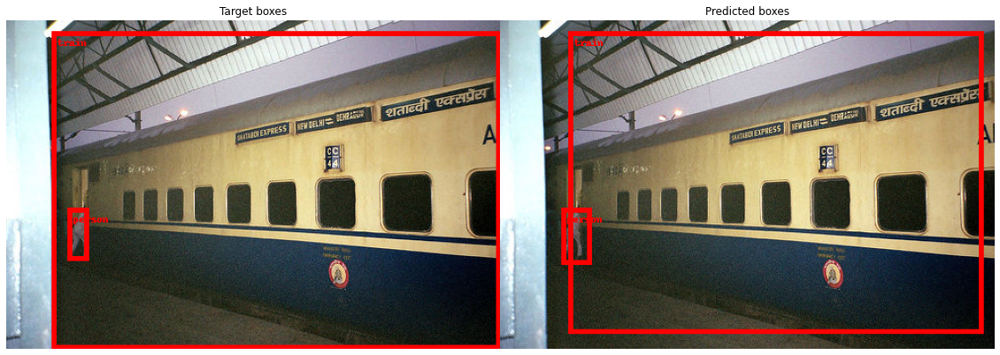

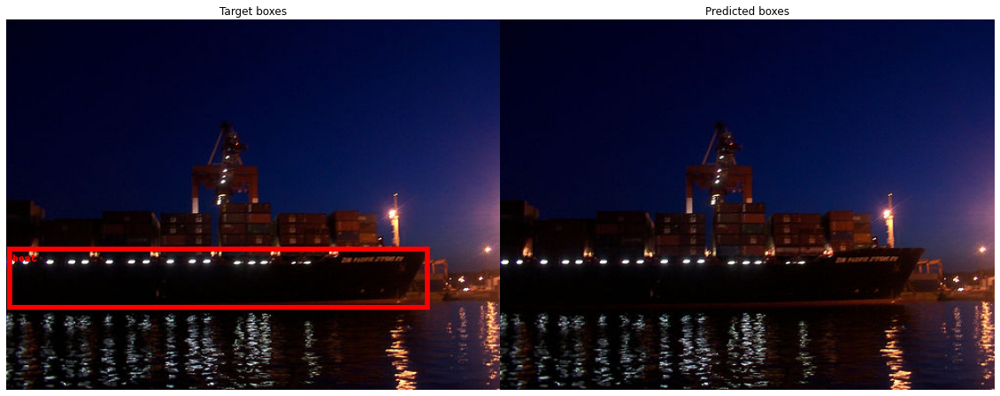

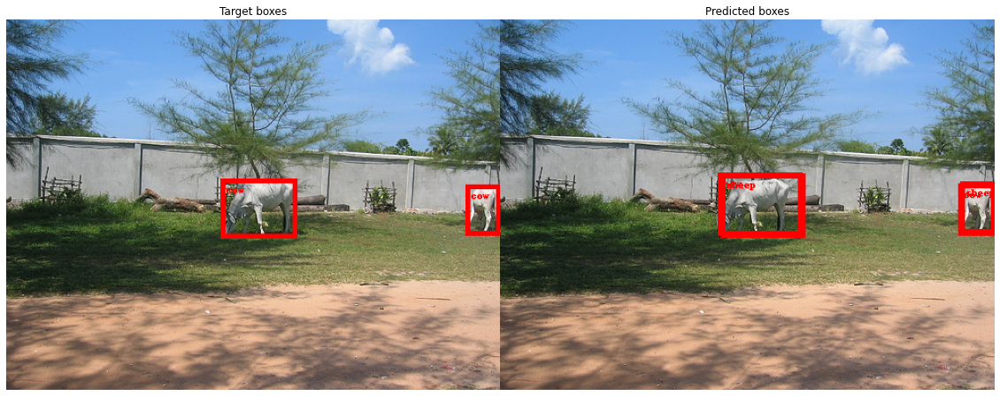

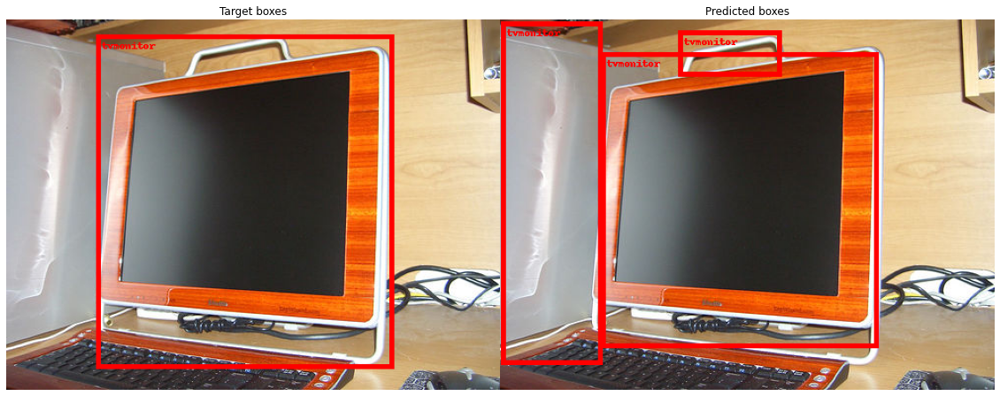

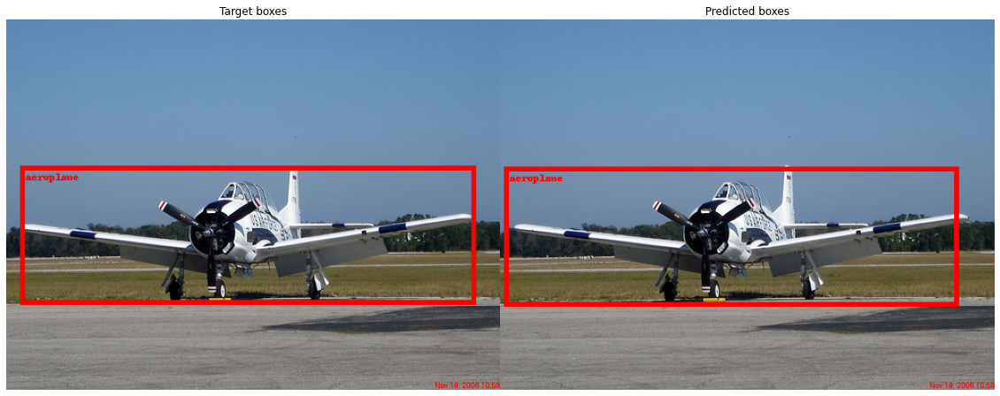

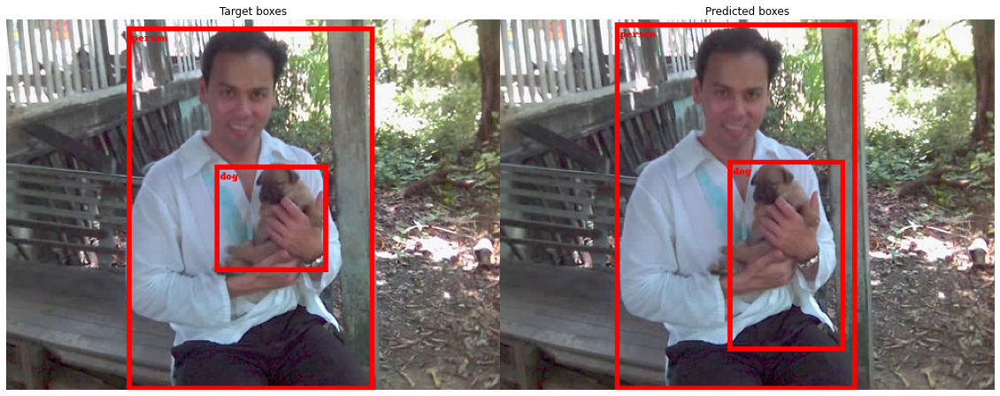

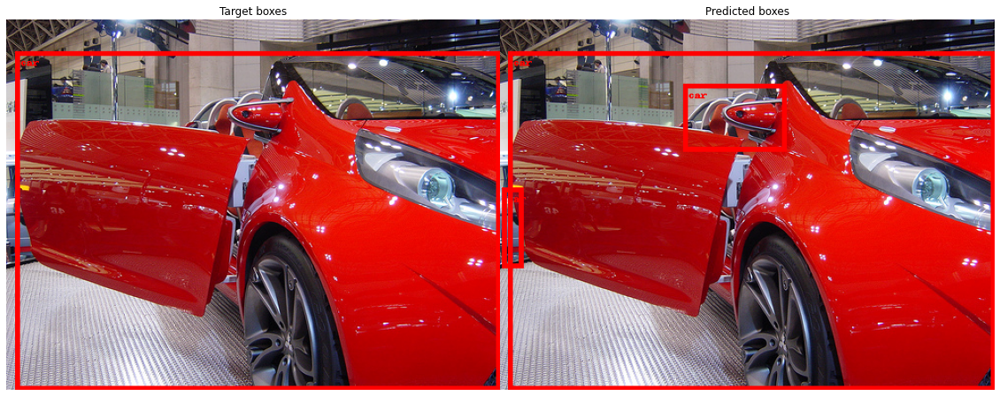

In [134]:
#!g1.1
whole_train_valid_cycle(model, 15, 'Faster R-CNN finetune')

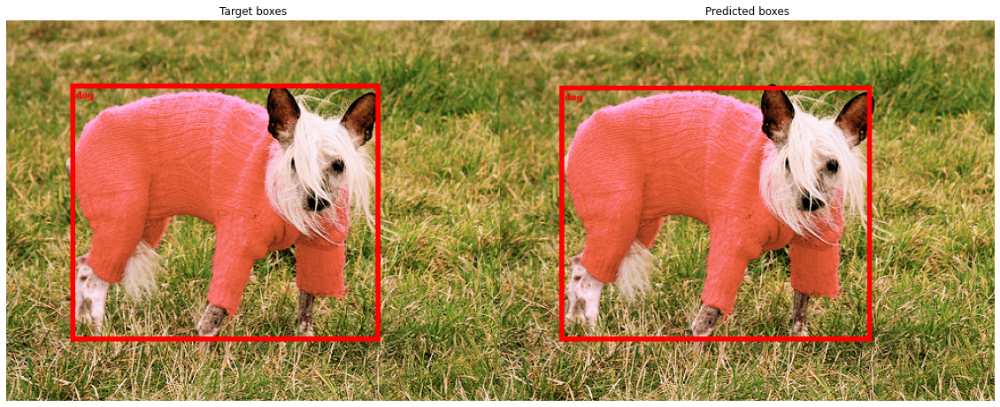

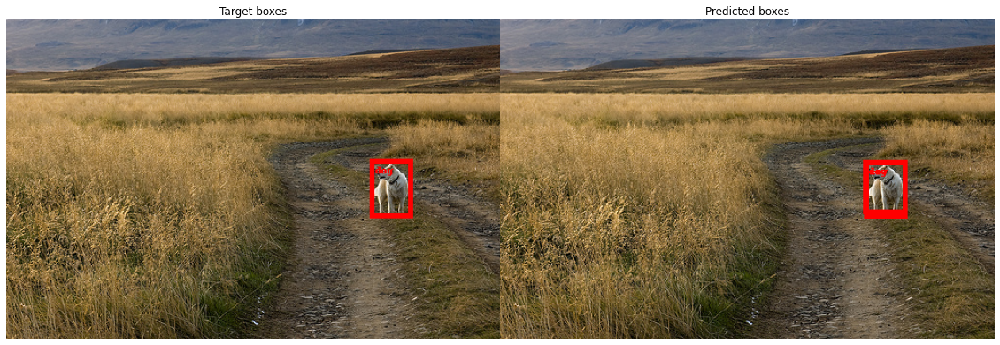

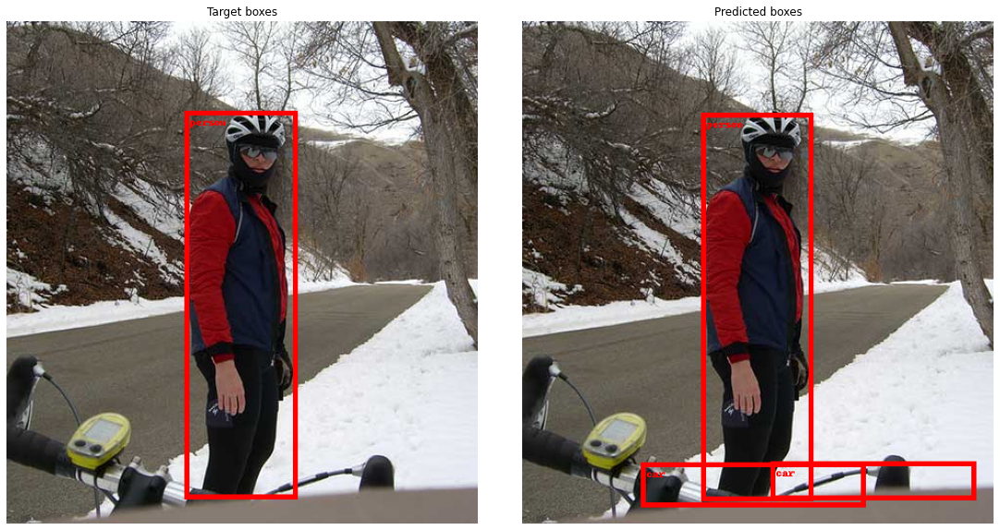

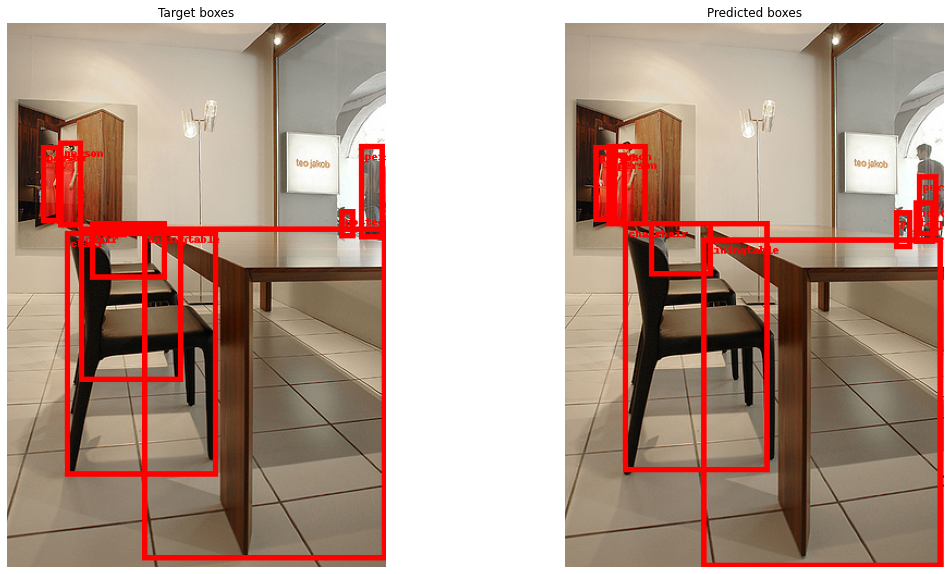

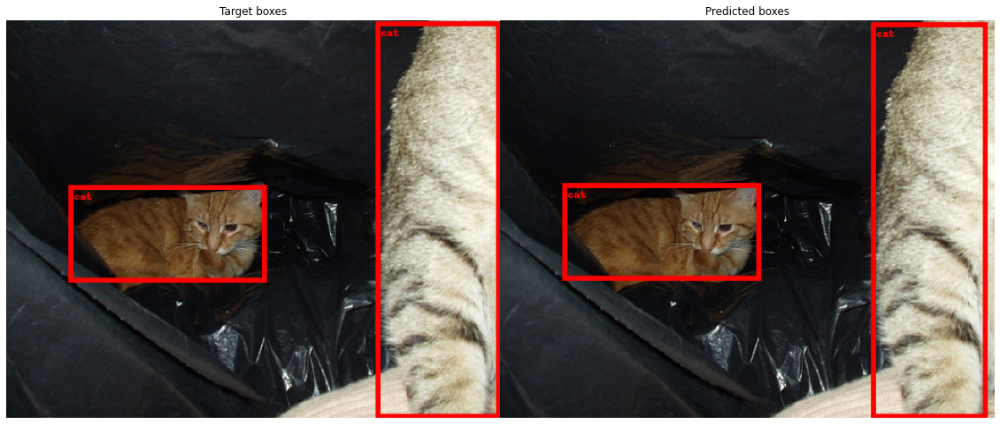

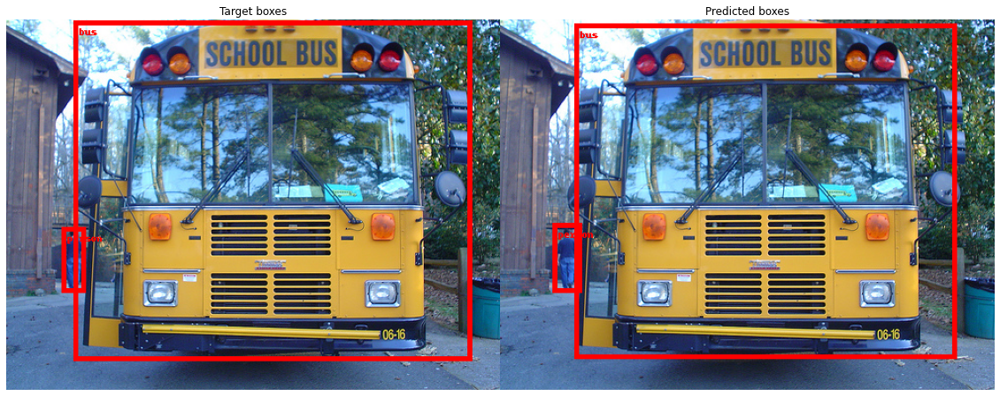

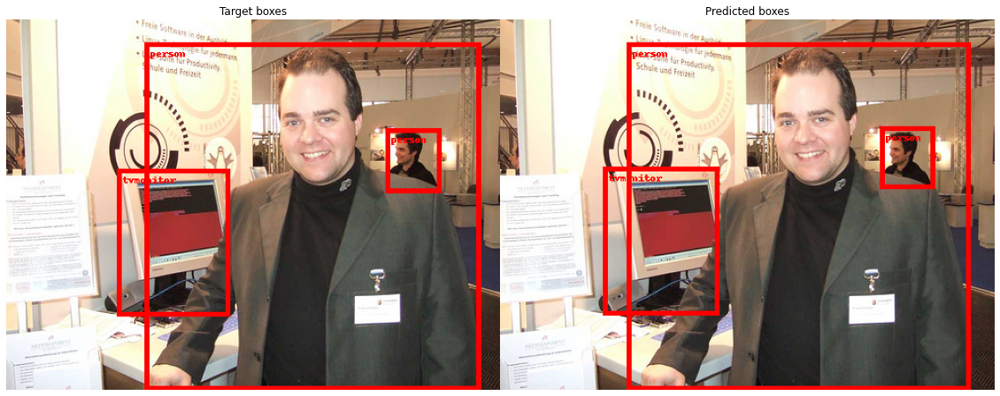

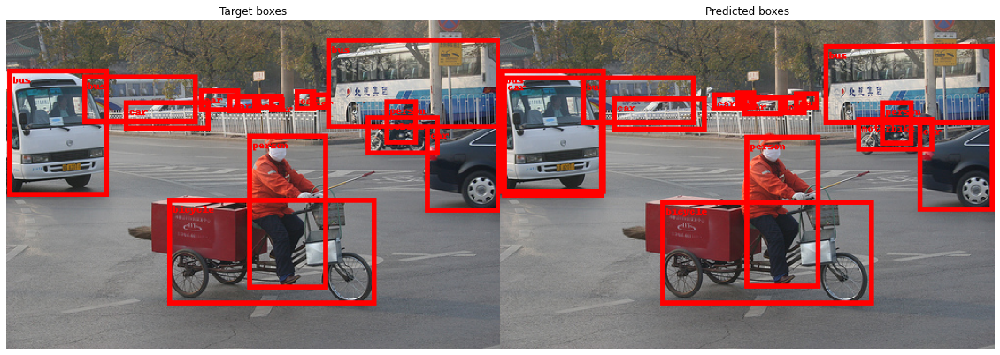

In [135]:
#!g1.1
visualize(model, next(iter(train_loader)))

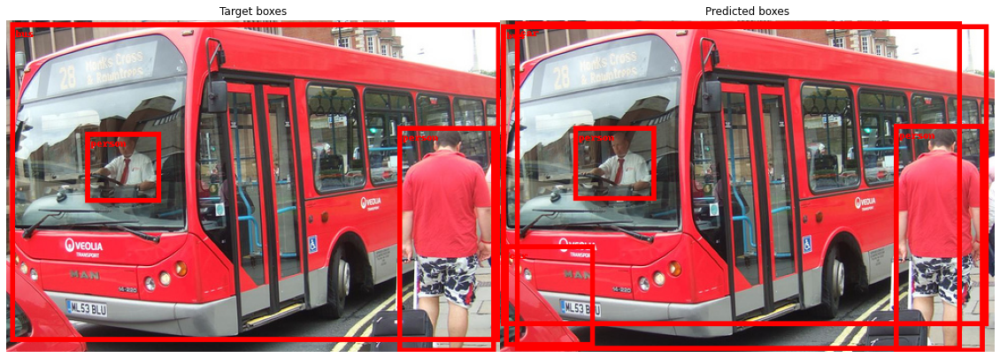

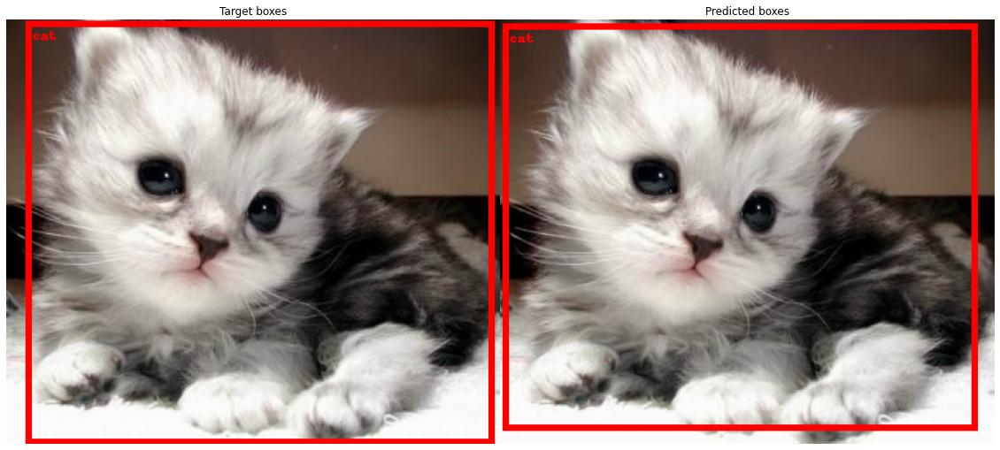

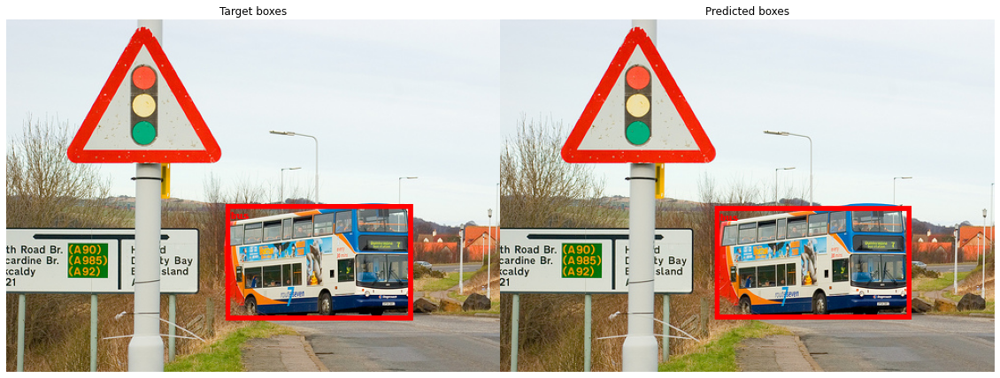

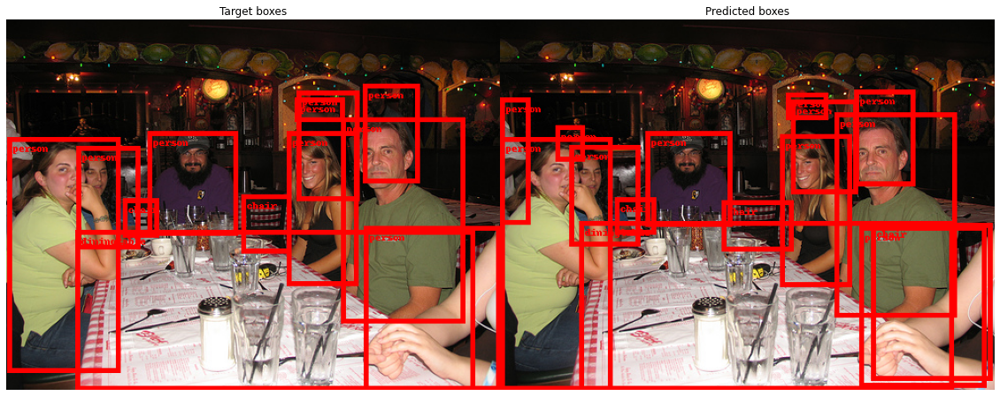

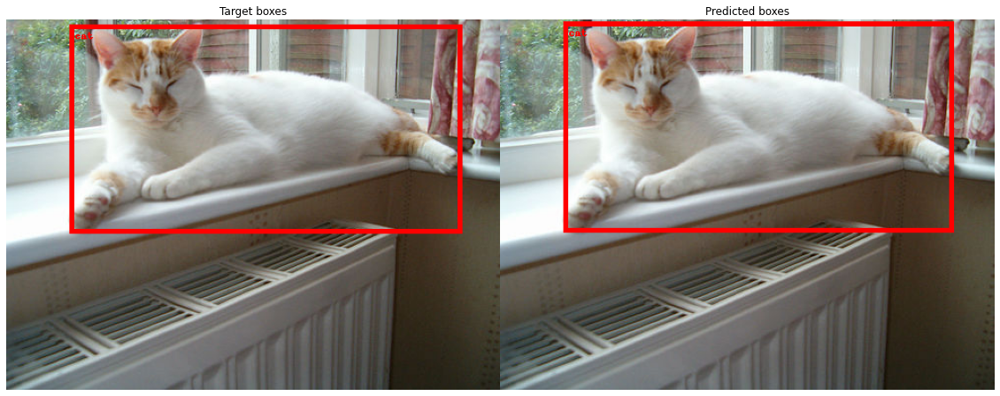

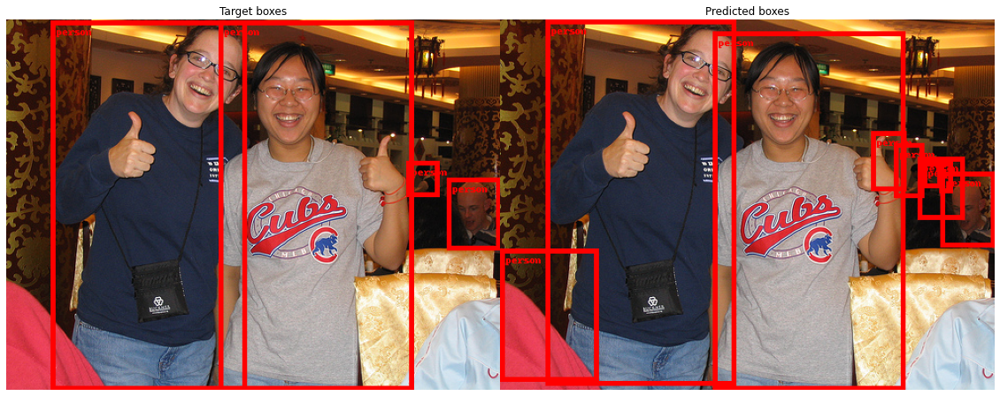

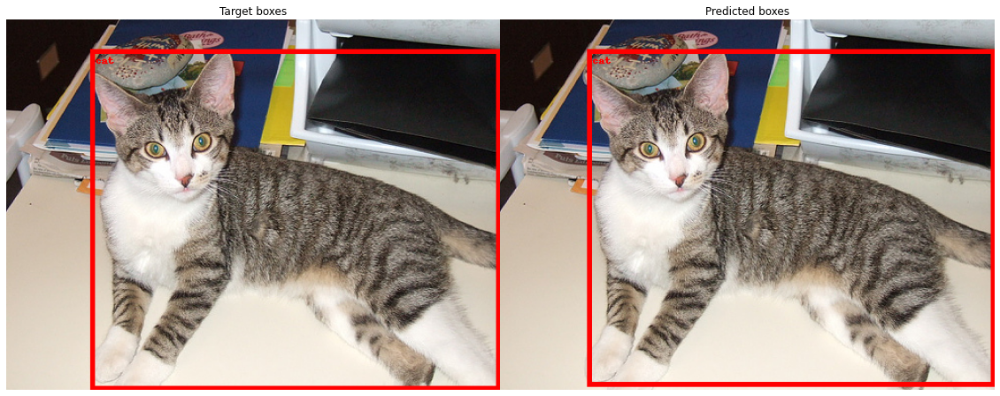

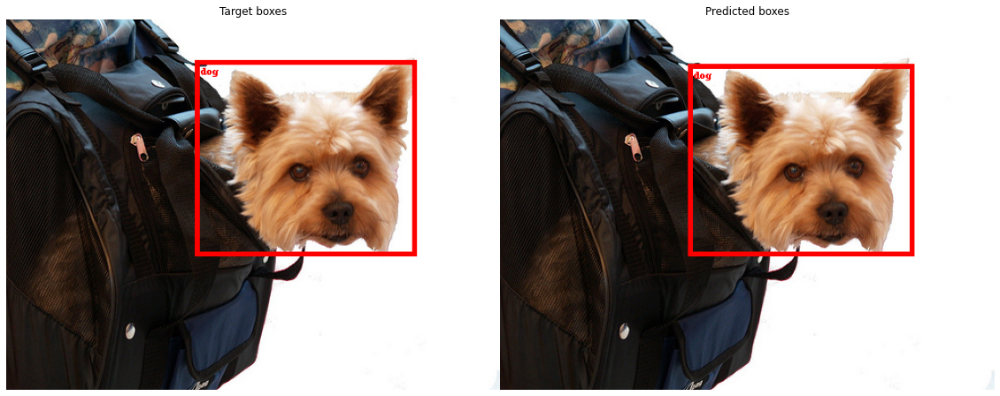

In [136]:
#!g1.1
visualize(model, next(iter(train_loader)))

In [137]:
#!g1.1
train_map = evaluate(model, train_loader)
valid_map = evaluate(model, valid_loader)

print(f'Train mAP {train_map:.5f} Valid mAP {valid_map:.5f}')

Evaluation: 100%|██████████| 728/728 [00:39<00:00, 18.34it/s]


Train mAP 0.67551 Valid mAP 0.37137



Мы успешно завершили изучение двух фундаментальных задач компьютерного зрения: **семантической сегментации** и **детекции объектов**.

**По семантической сегментации:**
*   Рассмотрели постановку задачи, метрики качества (Pixel Accuracy, IoU) и функцию потерь (Cross-Entropy Loss).
*   Изучили ключевые архитектуры: FCN с её принципами работы и ограничениями, а также U-Net, которая значительно улучшила качество за счёт "skip connections" и архитектуры "encoder-decoder".
*   На практике реализовали и обучили упрощённую модель U-Net на датасете Oxford Pets. Модель показала неплохие результаты, успешно выделяя объекты и их границы.
*   Отметили, что для дальнейшего повышения качества можно углубить/расширить сеть, использовать транспонированные свертки вместо интерполяции, а также более тщательно подбирать гиперпараметры и применять сложные аугментации данных.

**По детекции объектов:**
*   Изучили постановку задачи, ключевой алгоритм постобработки NMS (Non-Maximum Suppression) и важнейшие метрики качества (Precision, Recall, AP, mAP).
*   Разобрали эволюцию архитектур: от многоэтапных R-CNN, Fast R-CNN, Faster R-CNN (с их концепциями RPN, ROI Pooling и Anchor Boxes) до одноэтапных YOLO.
*   Практически дообучили (fine-tune) предобученную модель Faster R-CNN с бэкбоном MobileNetV3 на датасете PASCAL VOC.
*   Модель успешно предсказывает ограничивающие прямоугольники и классы объектов, как показано на визуализациях.
*   Полученные метрики (`Train mAP 0.67551`, `Valid mAP 0.37137`) указывают на то, что модель хорошо обучилась на тренировочных данных, но на валидационной выборке качество заметно ниже. Это является признаком **переобучения (overfitting)**. Для улучшения результатов и уменьшения разрыва между обучающей и валидационной метриками можно:
    *   Увеличить количество эпох обучения, но с более агрессивной стратегией регуляризации (например, ранней остановкой, если метрика на валидации перестает улучшаться).
    *   Настроить расписание скорости обучения (learning rate scheduler).
    *   Применить более сложные методы аугментации данных (случайное изменение яркости, контраста, повороты, масштабирования, обрезки).
    *   Увеличить размер батча или использовать более мощный бэкбон (с осторожностью, чтобы не усугубить переобучение).
    *   Тщательнее подобрать параметры NMS.

В целом, этот урок дал глубокое понимание принципов и практик работы с двумя ключевыми задачами компьютерного зрения, продемонстрировав мощь и гибкость нейронных сетей в решении сложных задач анализа изображений.